# DHd Blog Analysis

This notebook loads the scraped DHd Blog dataset, prepares the data, and reproduces the descriptive analyses and figures used in the project.


In [1]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import re

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from IPython.display import display
from nltk.corpus import stopwords
from scipy.stats import gaussian_kde
from wordcloud import WordCloud


# Project paths
# Supports notebooks/ + data/ repository layouts, the repository root,
# and notebooks opened directly in Google Colab.
PROJECT_ROOT = Path.cwd()
DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "dhd_blog_dataset.xlsx",
    PROJECT_ROOT.parent / "data" / "dhd_blog_dataset.xlsx",
    PROJECT_ROOT / "dhd_blog_dataset.xlsx",
    PROJECT_ROOT / "dhd_blog_complete.xlsx",
]

DATA_PATH = next(
    (path for path in DATA_CANDIDATES if path.exists()),
    None
)

if DATA_PATH is None:
    checked_paths = "\n".join(
        f"  - {path.resolve()}" for path in DATA_CANDIDATES
    )
    raise FileNotFoundError(
        "The DHd Blog dataset could not be found. Checked:\n"
        f"{checked_paths}\n\n"
        "Place dhd_blog_dataset.xlsx in the data folder or beside this notebook."
    )

FIGURE_DIR = (
    PROJECT_ROOT.parent / "figures"
    if PROJECT_ROOT.name.lower() == "notebooks"
    else PROJECT_ROOT / "figures"
)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(DATA_PATH)

print(f"Dataset: {DATA_PATH.resolve()}")
print(f"Shape: {df.shape}")
display(df.head())


Dataset: C:\Users\jiwani\Documents\dhd-blog-analysis\data\dhd_blog_dataset.xlsx
Shape: (2752, 18)


,post_id,url,archive_month,archive_page,archive_page_url,title,publication_date,year,month,author,categories,category_count,tags,tag_count,comments,word_count,text,text_starts_with_title
0,23954,https://dhd-blog.org/?p=23954,Juli 2026,1,https://dhd-blog.org/?m=202607,Bewerben bis 31.07.: Wiss. Mitarbeiter*in im P...,2026-07-16,2026,7,Christian Wachter,Stellenanzeigen,1,digital philosophy | Digitale Edition | Digita...,5,0,439,Am Philosophischen Seminar im Fachbereich 08 d...,0.0
1,23956,https://dhd-blog.org/?p=23956,Juli 2026,1,https://dhd-blog.org/?m=202607,Bewerben bis 10.08.2026: Akad. Rätin/Akad. Rat...,2026-07-21,2026,7,Christian Wachter,Stellenanzeigen,1,Digital History | Stelle | Stellenangebot,3,0,42,Am Historischen Seminar der Universität Münste...,0.0
2,23983,https://dhd-blog.org/?p=23983,Juli 2026,1,https://dhd-blog.org/?m=202607,Lecture: Tackling Data Gaps in Digital Humanit...,2026-07-28,2026,7,Polina Solonets,Allgemein | Veranstaltungen | Vortrag,3,NaN,0,0,280,We invite you to the online lecture by Dr. Sar...,0.0
3,23993,https://dhd-blog.org/?p=23993,Juli 2026,1,https://dhd-blog.org/?m=202607,Call for Hosts DHd2029,2026-07-29,2026,7,Vivien Wolter,Call | Konferenz,2,NaN,0,0,495,"DHd20xx ist die jährliche, internationale Fach...",0.0
4,23987,https://dhd-blog.org/?p=23987,Juli 2026,1,https://dhd-blog.org/?m=202607,30. AWK: Data Ethics for Archival Science and ...,2026-07-28,2026,7,Robert Meier,Allgemein,1,Datenethik,1,0,205,Im Ausland ist Datenethik bereits ein großes T...,0.0


In [2]:
# Work on a copy
analysis_df = df.copy()

# Ensure correct data types
analysis_df["publication_date"] = pd.to_datetime(
    analysis_df["publication_date"],
    errors="coerce"
)

analysis_df["year"] = analysis_df["publication_date"].dt.year
analysis_df["month"] = analysis_df["publication_date"].dt.month
analysis_df["month_name"] = analysis_df["publication_date"].dt.month_name()

analysis_df["word_count"] = pd.to_numeric(
    analysis_df["word_count"],
    errors="coerce"
).fillna(0)

analysis_df["comments"] = pd.to_numeric(
    analysis_df["comments"],
    errors="coerce"
).fillna(0)

analysis_df["categories"] = analysis_df["categories"].fillna("")
analysis_df["tags"] = analysis_df["tags"].fillna("")
analysis_df["text"] = analysis_df["text"].fillna("")
analysis_df["author"] = analysis_df["author"].fillna("Unknown")

# Remove accidental duplicate posts
analysis_df = analysis_df.drop_duplicates(
    subset="post_id"
).reset_index(drop=True)

print("Total posts:", len(analysis_df))
print("Date range:", analysis_df["publication_date"].min(),
      "to", analysis_df["publication_date"].max())
print("Authors:", analysis_df["author"].nunique())
print("Posts with categories:",
      analysis_df["categories"].str.strip().ne("").sum())
print("Posts with tags:",
      analysis_df["tags"].str.strip().ne("").sum())


Total posts: 2752
Date range: 2011-12-01 00:00:00 to 2026-07-29 00:00:00
Authors: 379
Posts with categories: 2750
Posts with tags: 2037


## 2. Posts per year

findfont: Failed to find font weight medium, now using 400.
findfont: Failed to find font weight medium, now using 400.


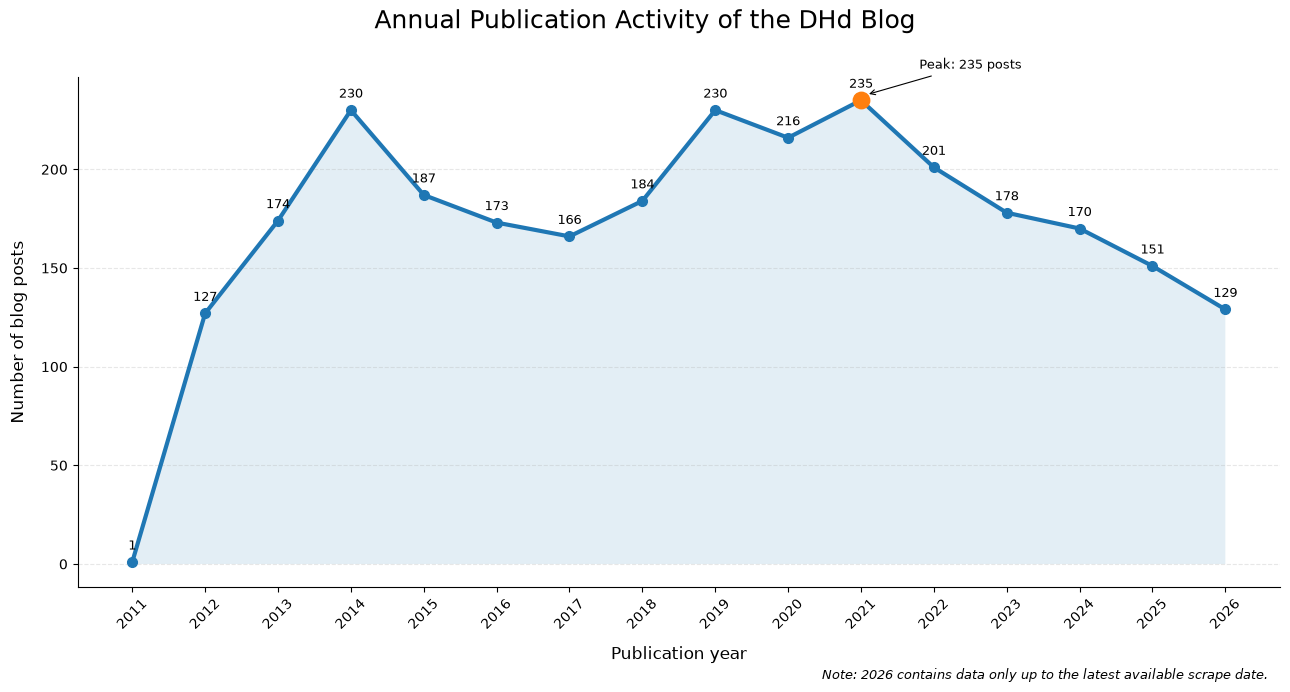

In [3]:
# Prepare data
posts_per_year = (
    analysis_df
    .groupby("year")
    .size()
    .reset_index(name="posts")
    .dropna()
)

posts_per_year["year"] = posts_per_year["year"].astype(int)

# Identify peak year
peak_row = posts_per_year.loc[
    posts_per_year["posts"].idxmax()
]

peak_year = int(peak_row["year"])
peak_posts = int(peak_row["posts"])

# Create chart
fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    posts_per_year["year"],
    posts_per_year["posts"],
    linewidth=3,
    marker="o",
    markersize=7
)

ax.fill_between(
    posts_per_year["year"],
    posts_per_year["posts"],
    alpha=0.12
)

# Add value labels
for _, row in posts_per_year.iterrows():
    ax.annotate(
        f"{int(row['posts'])}",
        (row["year"], row["posts"]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9
    )

# Highlight the peak
ax.scatter(
    peak_year,
    peak_posts,
    s=140,
    zorder=5
)

ax.annotate(
    f"Peak: {peak_posts} posts",
    xy=(peak_year, peak_posts + 2),
    xytext=(peak_year + 0.8, peak_posts + 16),   # Closer
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8,
        shrinkA=4,
        shrinkB=6
    ),
    zorder=10,
    fontsize=9,
    fontweight="medium",
    fontfamily="DejaVu Sans",
)

# Title and subtitle
fig.suptitle(
    "Annual Publication Activity of the DHd Blog",
    fontsize=18,
    fontweight="medium",
    fontfamily="DejaVu Sans",
    y=0.99
)

plt.subplots_adjust(top=0.88)   # more space between title and chart


# Axis labels
ax.set_xlabel(
    "Publication year",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Number of blog posts",
    fontsize=12,
    labelpad=10
)

# Ticks
ax.set_xticks(posts_per_year["year"])
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="both", labelsize=10)

# Grid and styling
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Note for incomplete year
if 2026 in posts_per_year["year"].values:
    ax.text(
        0.99,
        -0.18,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic"
    )

plt.tight_layout()

# Save high-quality image
plt.savefig(
    FIGURE_DIR / "fig01_dhd_posts_per_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3. Posts per month

findfont: Failed to find font weight medium, now using 400.


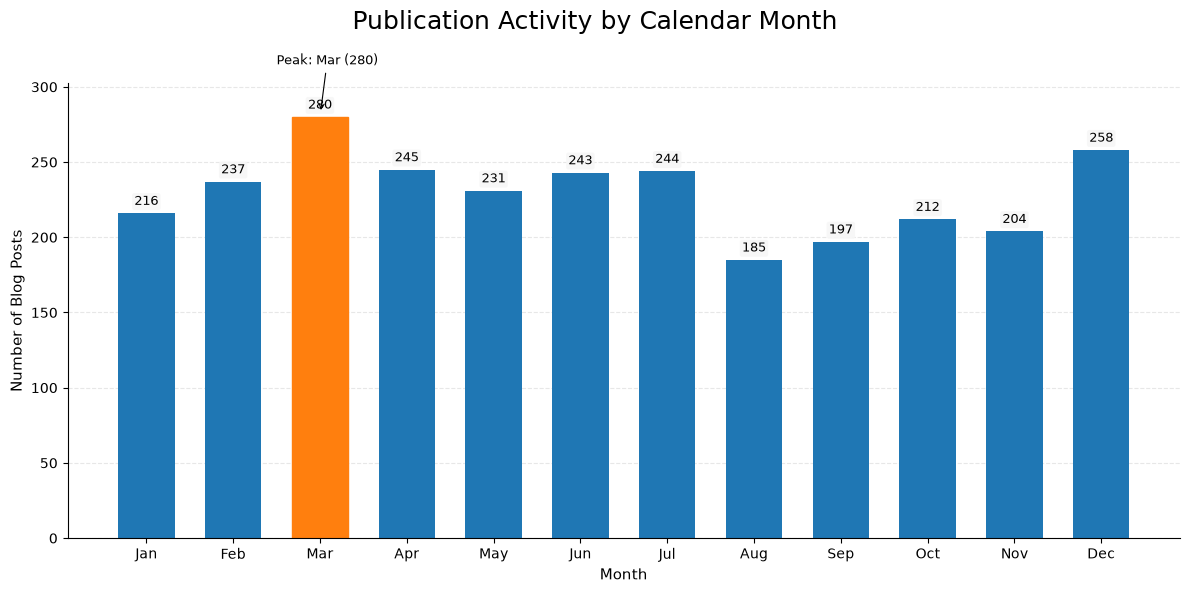

In [4]:
# Prepare data
posts_by_month = (
    analysis_df
    .groupby("month")
    .size()
    .reindex(range(1, 13), fill_value=0)
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Highest month
peak_month = posts_by_month.idxmax()
peak_posts = posts_by_month.max()

# Create chart
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    month_labels,
    posts_by_month.values,
    width=0.65
)

# Highlight busiest month
bars[peak_month - 1].set_color("tab:orange")

# Add value labels
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f7f7f7",
            edgecolor="none",
            alpha=0.9
        )
    )

# Annotate busiest month
ax.annotate(
    f"Peak: {month_labels[peak_month-1]} ({peak_posts})",
    xy=(peak_month-1, peak_posts),
    xytext=(peak_month-1.5, peak_posts+35),
    fontsize=9,
    fontweight="medium",
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8,
        shrinkA=4,
        shrinkB=5
    ),
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=0.3
    )
)

# Title
fig.suptitle(
    "Publication Activity by Calendar Month",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

plt.subplots_adjust(top=0.88)

# Axis labels
ax.set_xlabel(
    "Month",
    fontsize=11
)

ax.set_ylabel(
    "Number of Blog Posts",
    fontsize=11
)

# Styling
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=10)

ax.margins(y=0.08)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig02_posts_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 4. Top Categories

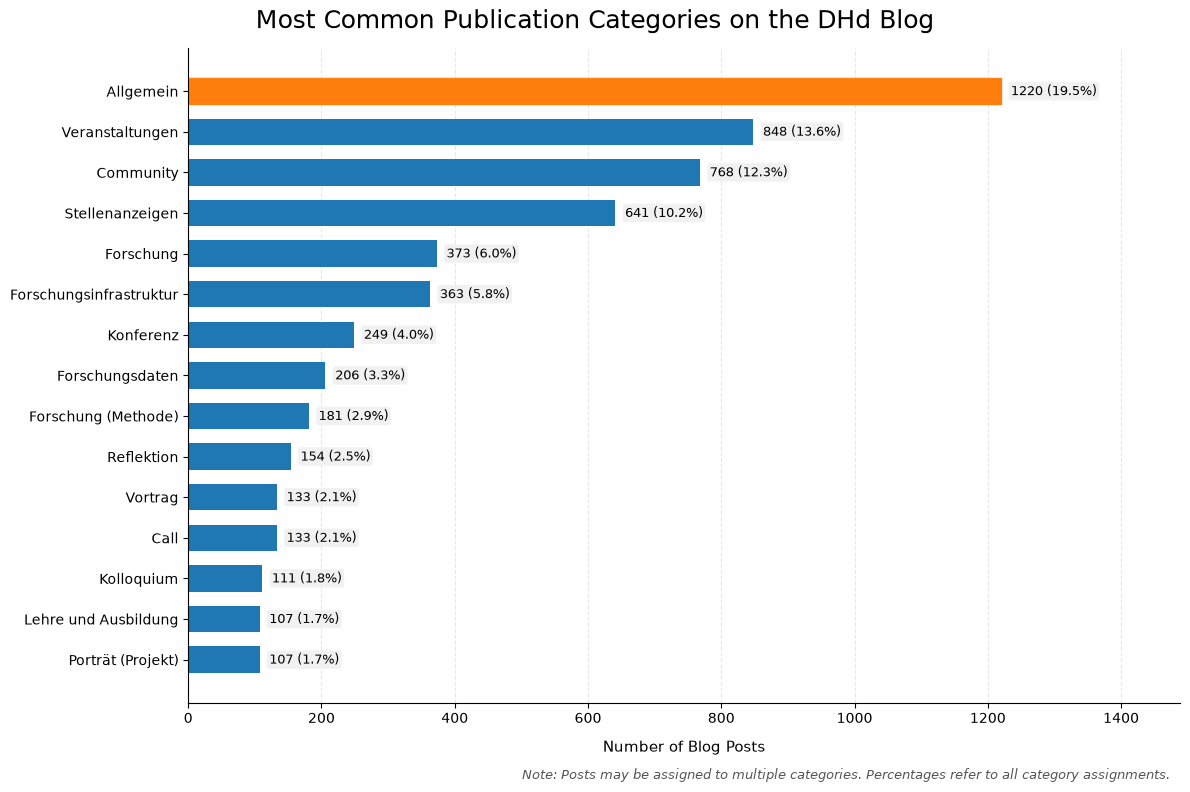

,category,posts,percentage
14,Allgemein,1220,19.498162
13,Veranstaltungen,848,13.552821
12,Community,768,12.274253
11,Stellenanzeigen,641,10.244526
10,Forschung,373,5.961323
9,Forschungsinfrastruktur,363,5.801502
8,Konferenz,249,3.979543
7,Forschungsdaten,206,3.292313
6,Forschung (Methode),181,2.892760
5,Reflektion,154,2.461243


In [5]:
# ------------------------------------------------------------
# Prepare category data
# ------------------------------------------------------------

category_df = (
    analysis_df[
        ["post_id", "year", "publication_date", "categories"]
    ]
    .assign(
        category=lambda x: (
            x["categories"]
            .fillna("")
            .str.split(r"\s*\|\s*")
        )
    )
    .explode("category")
)

category_df["category"] = (
    category_df["category"]
    .fillna("")
    .str.strip()
)

category_df = category_df[
    category_df["category"] != ""
].copy()

# Count categories
category_counts = (
    category_df["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="posts")
)

# Total category assignments
# A post may have more than one category.
total_category_assignments = category_counts["posts"].sum()

# Select top 15 categories
top_categories = (
    category_counts
    .head(15)
    .copy()
)

# Percentage is based on all category assignments
top_categories["percentage"] = (
    top_categories["posts"]
    / total_category_assignments
    * 100
)

# Sort ascending so the largest category appears at the top
top_categories = top_categories.sort_values(
    "posts",
    ascending=True
).reset_index(drop=True)

# ------------------------------------------------------------
# Create chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    top_categories["category"],
    top_categories["posts"],
    height=0.65
)

# Highlight the largest category
bars[-1].set_color("tab:orange")

# Add count and percentage labels
for bar, posts, percentage in zip(
    bars,
    top_categories["posts"],
    top_categories["percentage"]
):
    ax.annotate(
        f"{int(posts)} ({percentage:.1f}%)",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        ha="left",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# ------------------------------------------------------------
# Title and labels
# ------------------------------------------------------------

fig.suptitle(
    "Most Common Publication Categories on the DHd Blog",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Number of Blog Posts",
    fontsize=11,
    labelpad=10
)

# The category names already explain the y-axis
ax.set_ylabel("")

# ------------------------------------------------------------
# Grid and styling
# ------------------------------------------------------------

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

# Give labels enough room to the right
maximum_posts = top_categories["posts"].max()

ax.set_xlim(
    0,
    maximum_posts * 1.22
)

# Methodological note
ax.text(
    0.99,
    -0.10,
    (
        "Note: Posts may be assigned to multiple categories. "
        "Percentages refer to all category assignments."
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality image
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "fig03_top_dhd_blog_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Optional: display the underlying values
display(
    top_categories[
        ["category", "posts", "percentage"]
    ].sort_values(
        "posts",
        ascending=False
    )
)


## 5. Word Count Distribution

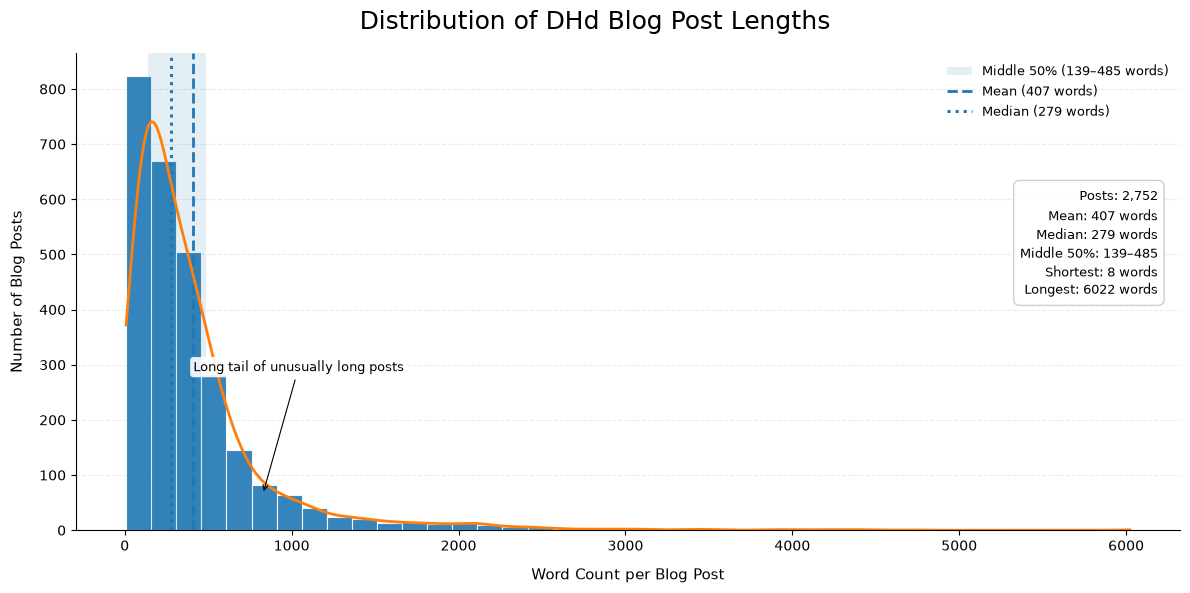

In [6]:
# ------------------------------------------------------------
# Prepare word-count data
# ------------------------------------------------------------

word_counts = (
    analysis_df["word_count"]
    .dropna()
    .astype(float)
)

mean_words = word_counts.mean()
median_words = word_counts.median()
q1 = word_counts.quantile(0.25)
q3 = word_counts.quantile(0.75)
min_words = word_counts.min()
max_words = word_counts.max()

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

# Histogram
counts, bins, patches = ax.hist(
    word_counts,
    bins=40,
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

# Shade the middle 50% of posts
ax.axvspan(
    q1,
    q3,
    alpha=0.12,
    label=f"Middle 50% ({q1:.0f}–{q3:.0f} words)"
)

# Mean and median lines
ax.axvline(
    mean_words,
    linestyle="--",
    linewidth=2,
    label=f"Mean ({mean_words:.0f} words)"
)

ax.axvline(
    median_words,
    linestyle=":",
    linewidth=2.2,
    label=f"Median ({median_words:.0f} words)"
)

# Smooth density curve scaled to histogram counts
density = gaussian_kde(word_counts)

x_values = np.linspace(
    word_counts.min(),
    word_counts.max(),
    400
)

bin_width = bins[1] - bins[0]

density_values = (
    density(x_values)
    * len(word_counts)
    * bin_width
)

ax.plot(
    x_values,
    density_values,
    linewidth=2
)

# ------------------------------------------------------------
# Summary statistics box
# ------------------------------------------------------------

summary_text = (
    f"Posts: {len(word_counts):,}\n"
    f"Mean: {mean_words:.0f} words\n"
    f"Median: {median_words:.0f} words\n"
    f"Middle 50%: {q1:.0f}–{q3:.0f}\n"
    f"Shortest: {min_words:.0f} words\n"
    f"Longest: {max_words:.0f} words"
)

ax.text(
    0.98,
    0.72,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    linespacing=1.5,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#cccccc",
        alpha=0.95
    )
)

# ------------------------------------------------------------
# Long-tail annotation
# ------------------------------------------------------------

tail_x = word_counts.quantile(0.90)

ax.annotate(
    "Long tail of unusually long posts",
    xy=(tail_x, max(counts) * 0.08),
    xytext=(word_counts.quantile(0.67), max(counts) * 0.35),
    fontsize=9,
    arrowprops=dict(
        arrowstyle="->",
        linewidth=0.8
    ),
    bbox=dict(
        boxstyle="round,pad=0.25",
        facecolor="white",
        edgecolor="none",
        alpha=0.9
    )
)

# ------------------------------------------------------------
# Title and labels
# ------------------------------------------------------------

fig.suptitle(
    "Distribution of DHd Blog Post Lengths",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Word Count per Blog Post",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Number of Blog Posts",
    fontsize=11,
    labelpad=10
)

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality figure
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "fig05_word_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Average Word Count by Year

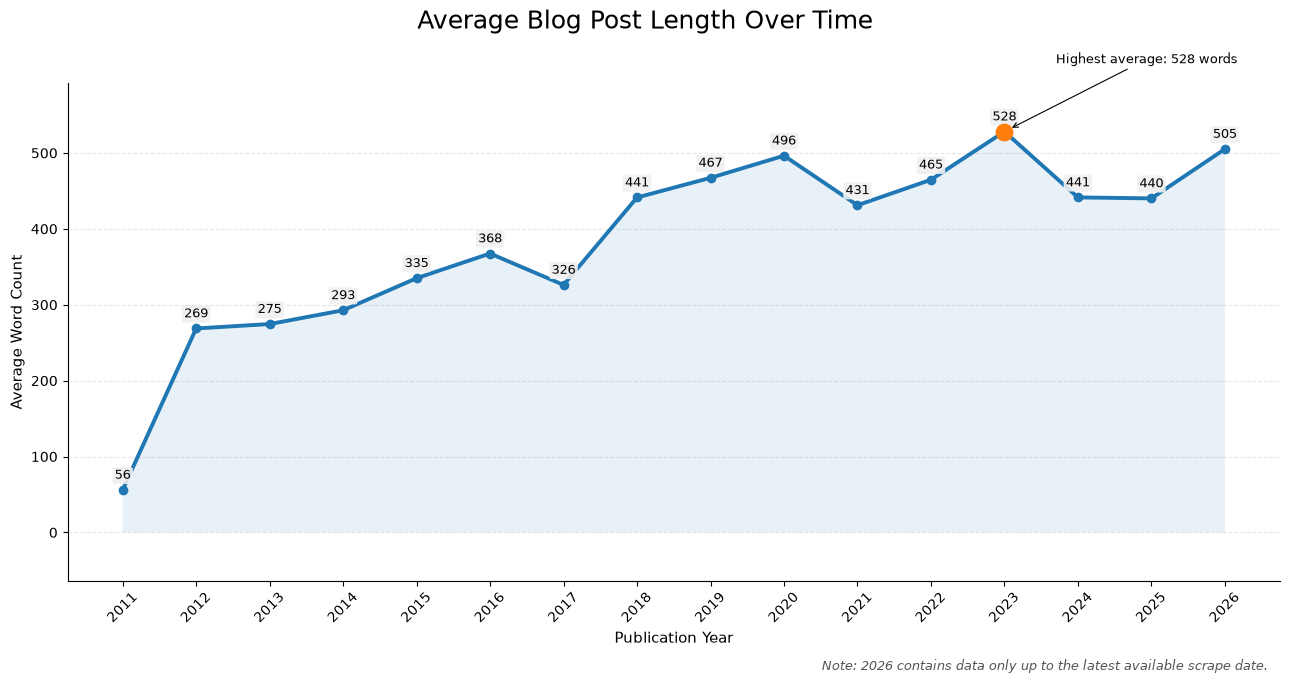

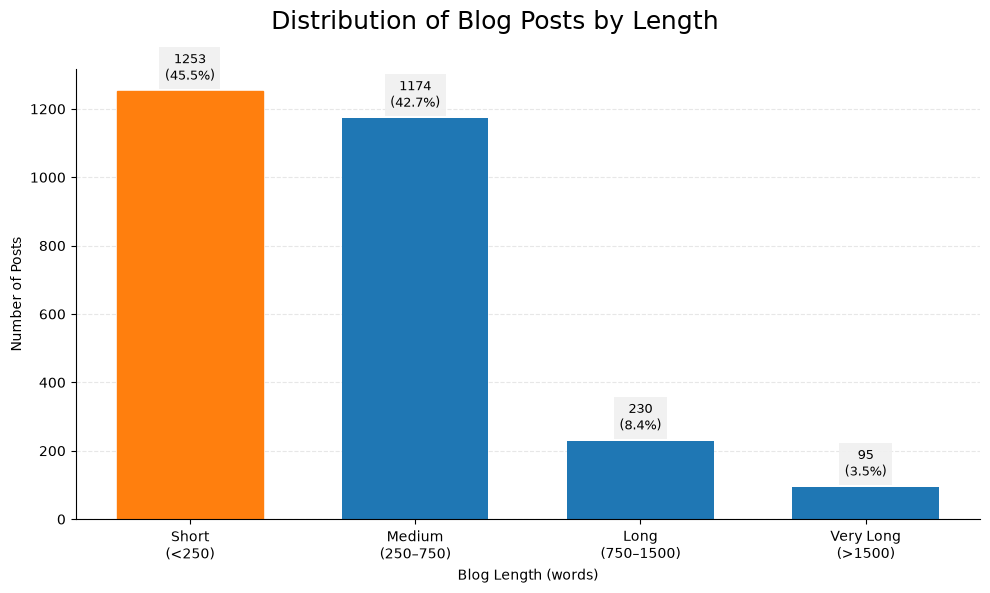

In [7]:
# ------------------------------------------------------------
# Average word count by year
# ------------------------------------------------------------

yearly_words = (
    analysis_df
    .groupby("year")["word_count"]
    .mean()
    .reset_index(name="avg_words")
)

yearly_words["year"] = yearly_words["year"].astype(int)

# Highest average
peak_row = yearly_words.loc[
    yearly_words["avg_words"].idxmax()
]

peak_year = int(peak_row["year"])
peak_words = peak_row["avg_words"]

# ------------------------------------------------------------
# Create chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    yearly_words["year"],
    yearly_words["avg_words"],
    linewidth=2.8,
    marker="o",
    markersize=6
)

ax.fill_between(
    yearly_words["year"],
    yearly_words["avg_words"],
    alpha=0.10
)

# ------------------------------------------------------------
# Add labels
# ------------------------------------------------------------

for _, row in yearly_words.iterrows():

    ax.annotate(
        f"{row['avg_words']:.0f}",
        xy=(row["year"], row["avg_words"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# ------------------------------------------------------------
# Highlight highest year
# ------------------------------------------------------------

ax.scatter(
    peak_year,
    peak_words,
    s=140,
    zorder=5
)

ax.annotate(
    f"Highest average: {peak_words:.0f} words",
    xy=(peak_year, peak_words),
    xytext=(peak_year + 0.7, peak_words + 90),
    fontsize=9,
    fontweight="medium",
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8,
        shrinkA=4,
        shrinkB=6
    ),
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9,
        pad=0.3
    )
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

fig.suptitle(
    "Average Blog Post Length Over Time",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

plt.subplots_adjust(top=0.88)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Publication Year",
    fontsize=11
)

ax.set_ylabel(
    "Average Word Count",
    fontsize=11
)

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------

ax.set_xticks(yearly_words["year"])

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.margins(y=0.12)

# ------------------------------------------------------------
# Note
# ------------------------------------------------------------

if 2026 in yearly_words["year"].values:
    ax.text(
        0.99,
        -0.18,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic",
        color="#555555"
    )

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "fig06_average_blog_post_length_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




# ============================================================
# Categorize blog lengths
# ============================================================

length_df = analysis_df.copy()

bins = [0, 250, 750, 1500, float("inf")]

labels = [
    "Short\n(<250)",
    "Medium\n(250–750)",
    "Long\n(750–1500)",
    "Very Long\n(>1500)"
]

length_df["length_category"] = pd.cut(
    length_df["word_count"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

length_counts = (
    length_df["length_category"]
    .value_counts(sort=False)
    .reset_index()
)

length_counts.columns = ["Category", "Posts"]

length_counts["Percentage"] = (
    length_counts["Posts"]
    / length_counts["Posts"].sum()
    * 100
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(
    length_counts["Category"],
    length_counts["Posts"],
    width=0.65
)

# Highlight largest group
bars[length_counts["Posts"].idxmax()].set_color("tab:orange")

for bar, pct in zip(bars, length_counts["Percentage"]):

    ax.annotate(
        f"{int(bar.get_height())}\n({pct:.1f}%)",
        xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
        xytext=(0,8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Distribution of Blog Posts by Length",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_xlabel("Blog Length (words)")
ax.set_ylabel("Number of Posts")

ax.grid(axis="y", linestyle="--", alpha=0.30)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig_length_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Most Active Author Contribution

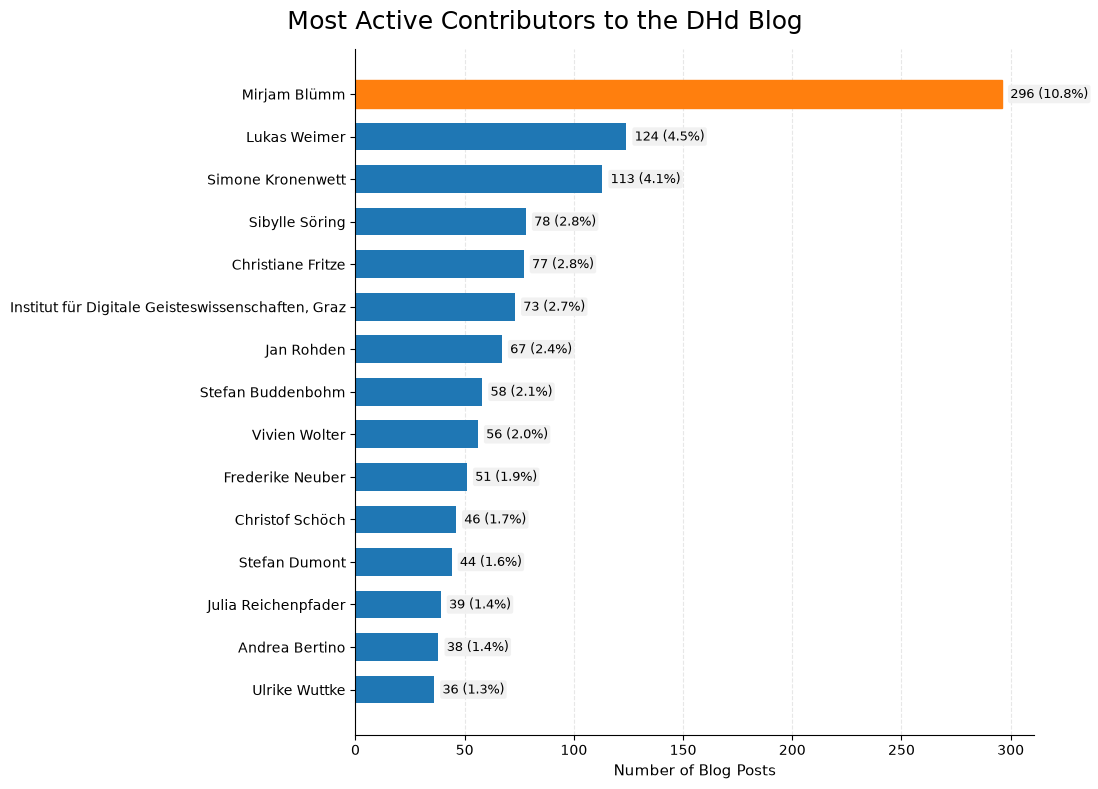

In [8]:
# ------------------------------------------------------------
# Top authors
# ------------------------------------------------------------

author_counts = (
    analysis_df["author"]
    .dropna()
    .value_counts()
    .reset_index()
)

author_counts.columns = ["author", "posts"]

top_authors = (
    author_counts
    .head(15)
    .sort_values("posts")
    .copy()
)

top_authors["percentage"] = (
    top_authors["posts"]
    / analysis_df.shape[0]
    * 100
)

# ------------------------------------------------------------
# Create chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    top_authors["author"],
    top_authors["posts"],
    height=0.65
)

# Highlight top contributor
bars[-1].set_color("tab:orange")

# Labels
for bar, posts, pct in zip(
    bars,
    top_authors["posts"],
    top_authors["percentage"]
):

    ax.annotate(
        f"{posts} ({pct:.1f}%)",
        xy=(bar.get_width(), bar.get_y()+bar.get_height()/2),
        xytext=(6,0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Active Contributors to the DHd Blog",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_xlabel("Number of Blog Posts", fontsize=11)
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.30)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig07_top_authors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 8. New Authors Joining the DHd Blog

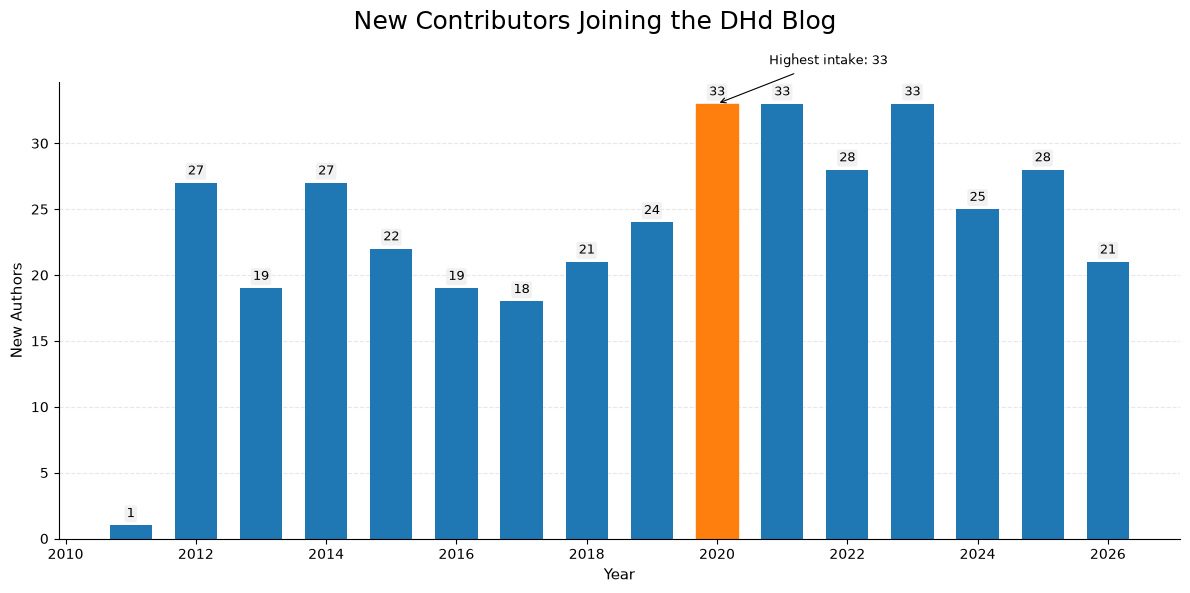

In [9]:
# ------------------------------------------------------------
# First appearance of every author
# ------------------------------------------------------------

first_author_year = (
    analysis_df
    .dropna(subset=["author"])
    .groupby("author")["year"]
    .min()
    .reset_index()
)

new_authors = (
    first_author_year
    .groupby("year")
    .size()
    .reset_index(name="new_authors")
)

# Highest year
peak = new_authors.loc[
    new_authors["new_authors"].idxmax()
]

peak_year = int(peak["year"])
peak_value = int(peak["new_authors"])

# ------------------------------------------------------------
# Chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12,6))

bars = ax.bar(
    new_authors["year"],
    new_authors["new_authors"],
    width=0.65
)

bars[
    new_authors["new_authors"].idxmax()
].set_color("tab:orange")

# Labels
for bar in bars:

    value = int(bar.get_height())

    ax.annotate(
        f"{value}",
        xy=(bar.get_x()+bar.get_width()/2, value),
        xytext=(0,6),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# Peak annotation
ax.annotate(
    f"Highest intake: {peak_value}",
    xy=(peak_year, peak_value),
    xytext=(peak_year+0.8, peak_value+3),
    fontsize=9,
    arrowprops=dict(
        arrowstyle="->",
        lw=0.8
    ),
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.9
    )
)

fig.suptitle(
    "New Contributors Joining the DHd Blog",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("New Authors", fontsize=11)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig08_new_authors_per_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Top 20 Tags and Tags Co-occurence Heatmap

Unique tags: 1752
Posts with at least one tag: 2037


,tag,posts,percentage
0,Stellenausschreibung,249,12.223859
1,Digital Humanities,240,11.782032
2,Berlin,216,10.603829
3,Digitale Edition,175,8.591065
4,DARIAH-DE,163,8.001964
5,Forschungsdaten,143,7.020128
6,Workshop,138,6.774669
7,TELOTA,119,5.841924
8,Text+,97,4.761905
9,TextGrid,84,4.123711


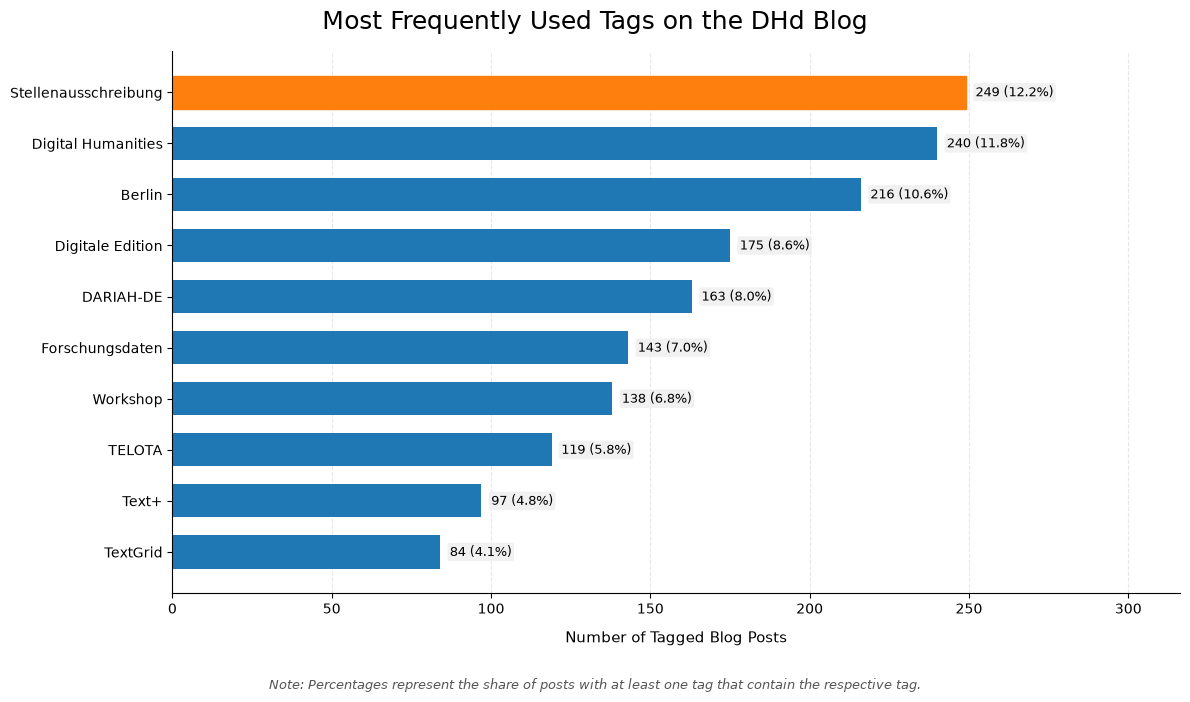

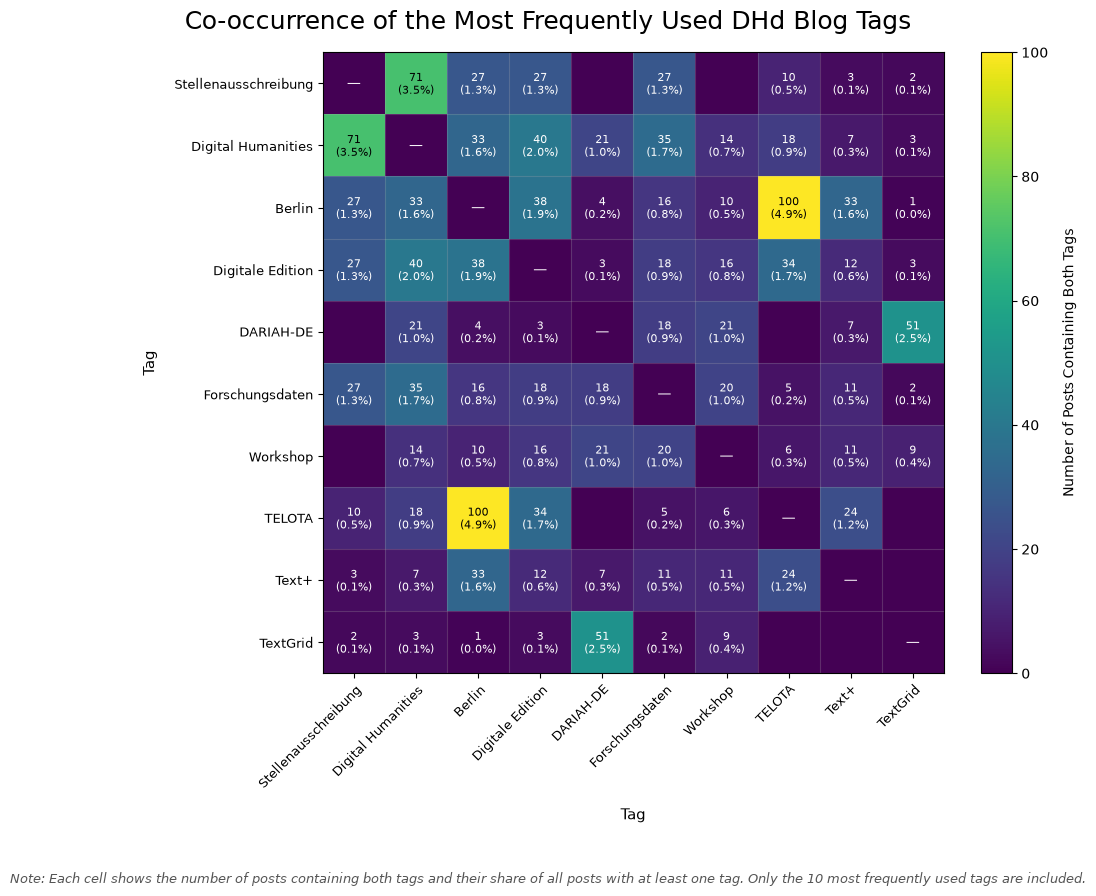

Top 10 strongest tag relationships:


,tag_1,tag_2,cooccurring_posts,percentage_of_tagged_posts
0,Berlin,TELOTA,100,4.9
1,Digital Humanities,Stellenausschreibung,71,3.5
2,DARIAH-DE,TextGrid,51,2.5
3,Digital Humanities,Digitale Edition,40,2.0
4,Berlin,Digitale Edition,38,1.9
5,Digital Humanities,Forschungsdaten,35,1.7
6,Digitale Edition,TELOTA,34,1.7
7,Berlin,Text+,33,1.6
8,Berlin,Digital Humanities,33,1.6
9,Digitale Edition,Stellenausschreibung,27,1.3


,Stellenausschreibung,Digital Humanities,Berlin,Digitale Edition,DARIAH-DE,Forschungsdaten,Workshop,TELOTA,Text+,TextGrid
Stellenausschreibung,NaN,28.5,10.8,10.8,0.0,10.8,0.0,4.0,1.2,0.8
Digital Humanities,29.6,NaN,13.8,16.7,8.8,14.6,5.8,7.5,2.9,1.2
Berlin,12.5,15.3,NaN,17.6,1.9,7.4,4.6,46.3,15.3,0.5
Digitale Edition,15.4,22.9,21.7,NaN,1.7,10.3,9.1,19.4,6.9,1.7
DARIAH-DE,0.0,12.9,2.5,1.8,NaN,11.0,12.9,0.0,4.3,31.3
Forschungsdaten,18.9,24.5,11.2,12.6,12.6,NaN,14.0,3.5,7.7,1.4
Workshop,0.0,10.1,7.2,11.6,15.2,14.5,NaN,4.3,8.0,6.5
TELOTA,8.4,15.1,84.0,28.6,0.0,4.2,5.0,NaN,20.2,0.0
Text+,3.1,7.2,34.0,12.4,7.2,11.3,11.3,24.7,NaN,0.0
TextGrid,2.4,3.6,1.2,3.6,60.7,2.4,10.7,0.0,0.0,NaN


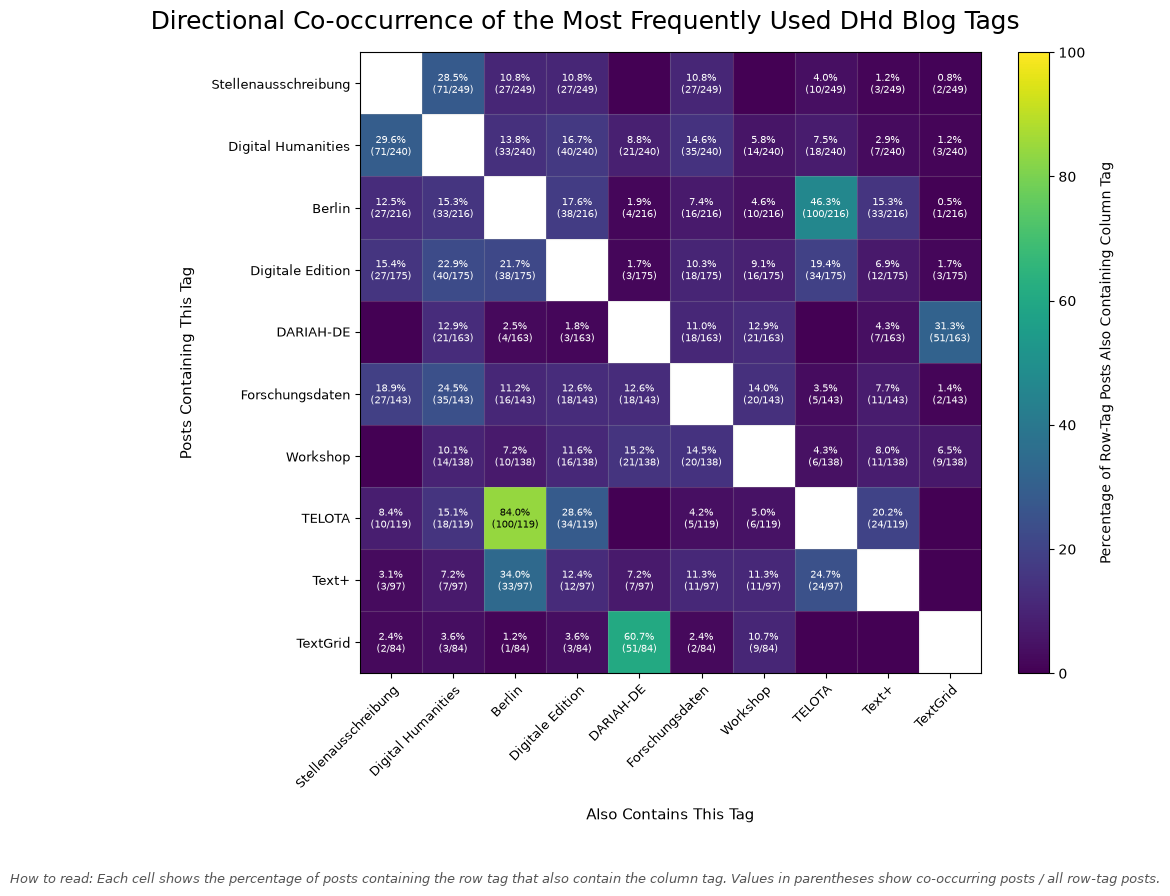

100 posts contain both 'TELOTA' and 'Berlin'.
TELOTA → Berlin: 84.0% of posts tagged 'TELOTA' are also tagged 'Berlin' (100/119).
Berlin → TELOTA: 46.3% of posts tagged 'Berlin' are also tagged 'TELOTA' (100/216).


In [11]:
# ============================================================
# 1. PREPARE CLEAN TAG DATA
# ============================================================

tag_source = analysis_df[
    ["post_id", "year", "tags"]
].copy()

tag_source["tags"] = (
    tag_source["tags"]
    .fillna("")
    .astype(str)
)

tag_df = (
    tag_source
    .assign(
        tag=lambda data:
        data["tags"].str.split(r"\s*\|\s*")
    )
    .explode("tag")
)

tag_df["tag"] = (
    tag_df["tag"]
    .fillna("")
    .str.strip()
)

# Remove empty tags
tag_df = tag_df[
    tag_df["tag"].ne("")
].copy()

# Count every post only once per tag
tag_df = tag_df.drop_duplicates(
    subset=["post_id", "tag"]
)

tag_counts = (
    tag_df
    .groupby("tag")["post_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("posts")
    .reset_index()
)

# Posts containing at least one tag
posts_with_tags = tag_df["post_id"].nunique()

tag_counts["percentage"] = (
    tag_counts["posts"]
    .div(posts_with_tags)
    .mul(100)
)

print("Unique tags:", tag_counts["tag"].nunique())
print("Posts with at least one tag:", posts_with_tags)

# Display only the top 10 tags
display(
    tag_counts
    .head(10)
    .reset_index(drop=True)
)


# ============================================================
# 2. FIGURE: TOP 10 TAGS
# ============================================================

top_10_tags = (
    tag_counts
    .head(10)
    .sort_values("posts")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_10_tags["tag"],
    top_10_tags["posts"],
    height=0.65
)

# Highlight the most frequent tag
bars[-1].set_color("tab:orange")

# Add count and percentage labels
for bar, posts, percentage in zip(
    bars,
    top_10_tags["posts"],
    top_10_tags["percentage"]
):
    ax.annotate(
        f"{int(posts)} ({percentage:.1f}%)",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Frequently Used Tags on the DHd Blog",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Number of Tagged Blog Posts",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.set_xlim(
    0,
    top_10_tags["posts"].max() * 1.27
)

fig.text(
    0.5,
    0.01,
    (
        "Note: Percentages represent the share of posts with at least "
        "one tag that contain the respective tag."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

plt.savefig(
    FIGURE_DIR / "fig09_top_10_dhd_blog_tags.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. BUILD CO-OCCURRENCES FOR TOP 10 TAGS
# ============================================================

heatmap_tags = (
    tag_counts
    .head(10)["tag"]
    .tolist()
)

heatmap_tag_set = set(heatmap_tags)

tag_pairs = Counter()

for tags_text in tag_source["tags"]:

    tags = {
        tag.strip()
        for tag in str(tags_text).split("|")
        if tag.strip()
    }

    # Keep only the selected top 10 tags
    selected_tags = sorted(
        tags.intersection(heatmap_tag_set)
    )

    for tag_1, tag_2 in combinations(
        selected_tags,
        2
    ):
        tag_pairs[(tag_1, tag_2)] += 1


# ============================================================
# 4. CREATE COUNT AND PERCENTAGE MATRICES
# ============================================================

cooccurrence_matrix = pd.DataFrame(
    0,
    index=heatmap_tags,
    columns=heatmap_tags,
    dtype=int
)

for (tag_1, tag_2), count in tag_pairs.items():

    cooccurrence_matrix.loc[
        tag_1,
        tag_2
    ] = count

    cooccurrence_matrix.loc[
        tag_2,
        tag_1
    ] = count

# Keep diagonal at zero because a tag cannot co-occur with itself
for tag in heatmap_tags:
    cooccurrence_matrix.loc[tag, tag] = 0

# Percentage of all tagged posts containing both tags
cooccurrence_percentage = (
    cooccurrence_matrix
    .div(posts_with_tags)
    .mul(100)
)


# ============================================================
# 5. FIGURE: TOP 10 TAG CO-OCCURRENCE HEATMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

image = ax.imshow(
    cooccurrence_matrix.to_numpy(),
    aspect="equal",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(heatmap_tags))
)

ax.set_xticklabels(
    heatmap_tags,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(heatmap_tags))
)

ax.set_yticklabels(
    heatmap_tags,
    fontsize=9
)

# ------------------------------------------------------------
# Add count and percentage to every non-zero cell
#
# Text colour is determined from the actual background colour:
# - dark cell  -> white text
# - light cell -> black text
# ------------------------------------------------------------

for row_index in range(len(heatmap_tags)):
    for column_index in range(len(heatmap_tags)):

        count = cooccurrence_matrix.iloc[
            row_index,
            column_index
        ]

        percentage = cooccurrence_percentage.iloc[
            row_index,
            column_index
        ]

        if count > 0:

            # Get the actual RGBA background colour of the cell
            red, green, blue, alpha = image.cmap(
                image.norm(count)
            )

            # Calculate perceived brightness
            luminance = (
                0.299 * red +
                0.587 * green +
                0.114 * blue
            )

            # White text on dark cells, black text on light cells
            text_color = (
                "black"
                if luminance > 0.55
                else "white"
            )

            ax.text(
                column_index,
                row_index,
                f"{count}\n({percentage:.1f}%)",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="normal",
                color=text_color,
                linespacing=1.15
            )

# Put a dash on the diagonal
for index in range(len(heatmap_tags)):

    diagonal_red, diagonal_green, diagonal_blue, _ = (
        image.cmap(
            image.norm(0)
        )
    )

    diagonal_luminance = (
        0.299 * diagonal_red +
        0.587 * diagonal_green +
        0.114 * diagonal_blue
    )

    diagonal_text_color = (
        "black"
        if diagonal_luminance > 0.55
        else "white"
    )

    ax.text(
        index,
        index,
        "—",
        ha="center",
        va="center",
        fontsize=10,
        color=diagonal_text_color
    )

# Add grid lines between cells
ax.set_xticks(
    np.arange(
        -0.5,
        len(heatmap_tags),
        1
    ),
    minor=True
)

ax.set_yticks(
    np.arange(
        -0.5,
        len(heatmap_tags),
        1
    ),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.8,
    alpha=0.25
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Add colour bar
colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Number of Posts Containing Both Tags",
    fontsize=10,
    labelpad=10
)

fig.suptitle(
    "Co-occurrence of the Most Frequently Used DHd Blog Tags",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Tag",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Tag",
    fontsize=11,
    labelpad=12
)

fig.text(
    0.5,
    0.01,
    (
        "Note: Each cell shows the number of posts containing both tags "
        "and their share of all posts with at least one tag. "
        "Only the 10 most frequently used tags are included."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.savefig(
    FIGURE_DIR / "fig10_top_10_tag_cooccurrence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. DISPLAY TOP 10 STRONGEST TAG PAIRS
# ============================================================

pair_df = pd.DataFrame(
    [
        {
            "tag_1": tag_1,
            "tag_2": tag_2,
            "cooccurring_posts": count,
            "percentage_of_tagged_posts": (
                count / posts_with_tags * 100
            )
        }
        for (tag_1, tag_2), count in tag_pairs.items()
    ]
)

if not pair_df.empty:

    pair_df = (
        pair_df
        .sort_values(
            "cooccurring_posts",
            ascending=False
        )
        .reset_index(drop=True)
    )

    pair_df["percentage_of_tagged_posts"] = (
        pair_df["percentage_of_tagged_posts"]
        .round(1)
    )

    print("Top 10 strongest tag relationships:")

    display(
        pair_df.head(10)
    )

else:

    print(
        "No co-occurring pairs were found among "
        "the selected top 10 tags."
    )


# ============================================================
# 7. CREATE DIRECTIONAL CONDITIONAL PERCENTAGE MATRIX
# ============================================================
#
# Each cell answers:
# "Of all posts containing the ROW tag, what percentage
# also contain the COLUMN tag?"
#
# Example:
# Row = TELOTA, Column = Berlin
# -> Percentage of TELOTA posts that also have Berlin
# ============================================================

# Total number of posts containing each selected tag
heatmap_tag_totals = (
    tag_df[
        tag_df["tag"].isin(heatmap_tags)
    ]
    .groupby("tag")["post_id"]
    .nunique()
    .reindex(heatmap_tags)
)

# Divide every row by the total number of posts containing
# that row's tag
conditional_percentage_matrix = (
    cooccurrence_matrix
    .div(heatmap_tag_totals, axis=0)
    .mul(100)
)

# Keep diagonal blank
for tag in heatmap_tags:
    conditional_percentage_matrix.loc[tag, tag] = np.nan

display(
    conditional_percentage_matrix.round(1)
)


# ============================================================
# 8. FIGURE: DIRECTIONAL TAG CO-OCCURRENCE HEATMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

image = ax.imshow(
    conditional_percentage_matrix.to_numpy(),
    aspect="equal",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(
    np.arange(len(heatmap_tags))
)

ax.set_xticklabels(
    heatmap_tags,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(heatmap_tags))
)

ax.set_yticklabels(
    heatmap_tags,
    fontsize=9
)

# ------------------------------------------------------------
# Add directional percentage, count, and denominator
# ------------------------------------------------------------

for row_index in range(len(heatmap_tags)):
    for column_index in range(len(heatmap_tags)):

        if row_index == column_index:
            ax.text(
                column_index,
                row_index,
                "—",
                ha="center",
                va="center",
                fontsize=10,
                color="white"
            )
            continue

        percentage = conditional_percentage_matrix.iloc[
            row_index,
            column_index
        ]

        count = cooccurrence_matrix.iloc[
            row_index,
            column_index
        ]

        row_total = heatmap_tag_totals.iloc[row_index]

        if pd.notna(percentage) and count > 0:

            red, green, blue, alpha = image.cmap(
                image.norm(percentage)
            )

            luminance = (
                0.299 * red +
                0.587 * green +
                0.114 * blue
            )

            text_color = (
                "black"
                if luminance > 0.55
                else "white"
            )

            ax.text(
                column_index,
                row_index,
                f"{percentage:.1f}%\n({count}/{row_total})",
                ha="center",
                va="center",
                fontsize=7.5,
                color=text_color,
                linespacing=1.15
            )

# Grid lines
ax.set_xticks(
    np.arange(-0.5, len(heatmap_tags), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(heatmap_tags), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.8,
    alpha=0.25
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Colour bar
colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Percentage of Row-Tag Posts Also Containing Column Tag",
    fontsize=10,
    labelpad=10
)

fig.suptitle(
    "Directional Co-occurrence of the Most Frequently Used DHd Blog Tags",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_xlabel(
    "Also Contains This Tag",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Posts Containing This Tag",
    fontsize=11,
    labelpad=12
)

fig.text(
    0.5,
    0.01,
    (
        "How to read: Each cell shows the percentage of posts containing "
        "the row tag that also contain the column tag. "
        "Values in parentheses show co-occurring posts / all row-tag posts."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.savefig(
    FIGURE_DIR / "fig11_directional_tag_cooccurrence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. EXAMPLE: TELOTA AND BERLIN IN BOTH DIRECTIONS
# ============================================================

tag_a = "TELOTA"
tag_b = "Berlin"

if (
    tag_a in cooccurrence_matrix.index
    and tag_b in cooccurrence_matrix.columns
):

    both_count = cooccurrence_matrix.loc[
        tag_a,
        tag_b
    ]

    tag_a_total = heatmap_tag_totals.loc[tag_a]
    tag_b_total = heatmap_tag_totals.loc[tag_b]

    tag_a_to_b = (
        both_count / tag_a_total * 100
    )

    tag_b_to_a = (
        both_count / tag_b_total * 100
    )

    print(
        f"{both_count} posts contain both "
        f"'{tag_a}' and '{tag_b}'."
    )

    print(
        f"{tag_a} → {tag_b}: "
        f"{tag_a_to_b:.1f}% of posts tagged '{tag_a}' "
        f"are also tagged '{tag_b}' "
        f"({both_count}/{tag_a_total})."
    )

    print(
        f"{tag_b} → {tag_a}: "
        f"{tag_b_to_a:.1f}% of posts tagged '{tag_b}' "
        f"are also tagged '{tag_a}' "
        f"({both_count}/{tag_b_total})."
    )

else:

    print(
        f"The example tags '{tag_a}' and/or '{tag_b}' "
        "are not present among the top 10 tags."
    )

## 10. Topic Trends

,topic,posts,percentage_of_all_posts
0,Research Data Management,814,29.578488
1,Cultural Heritage and Museums,768,27.906977
2,FAIR Data and Open Science,457,16.606105
3,Metadata and Data Modelling,444,16.133721
4,TEI and Text Encoding,425,15.443314
5,Digital Editions,356,12.936047
6,Text Corpora,283,10.283430
7,Linked Data and Knowledge Graphs,276,10.029070
8,Data Visualization,246,8.938953
9,NLP and Computational Linguistics,245,8.902616


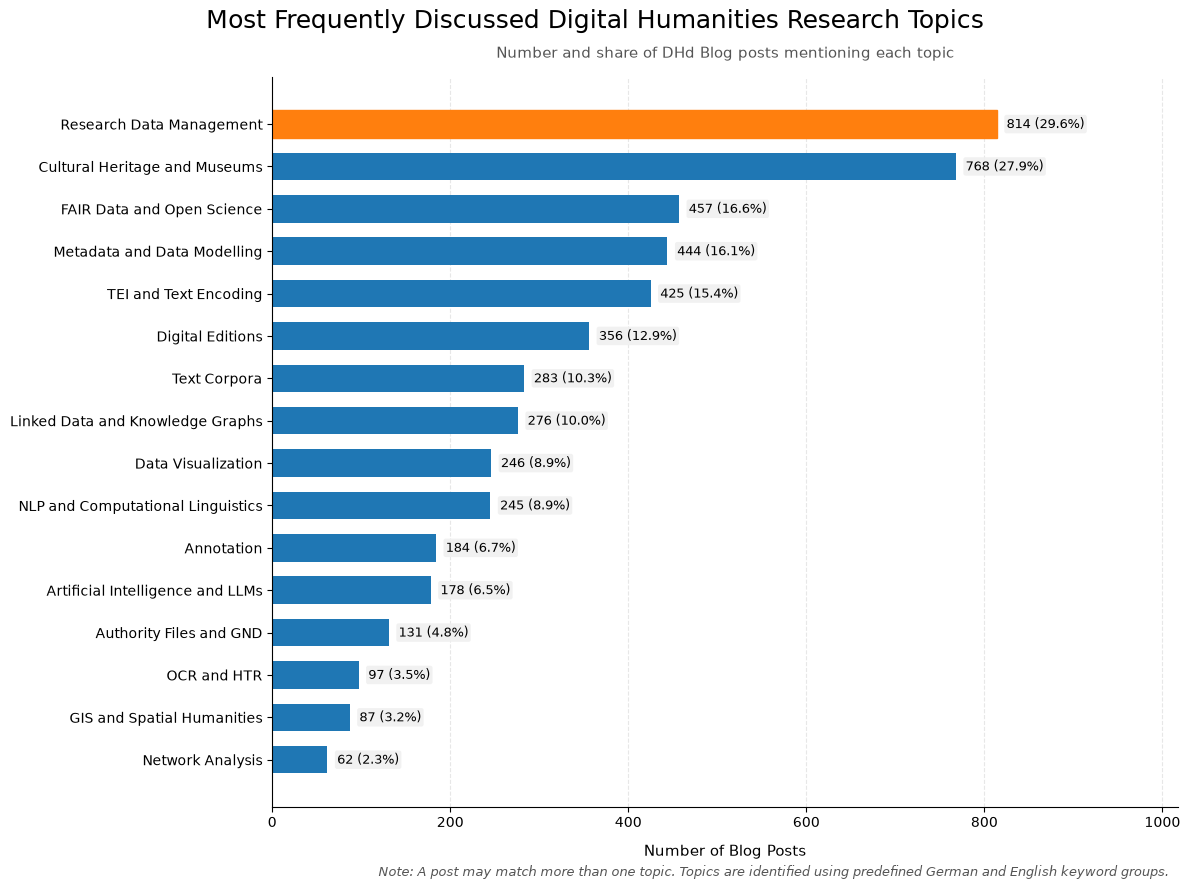

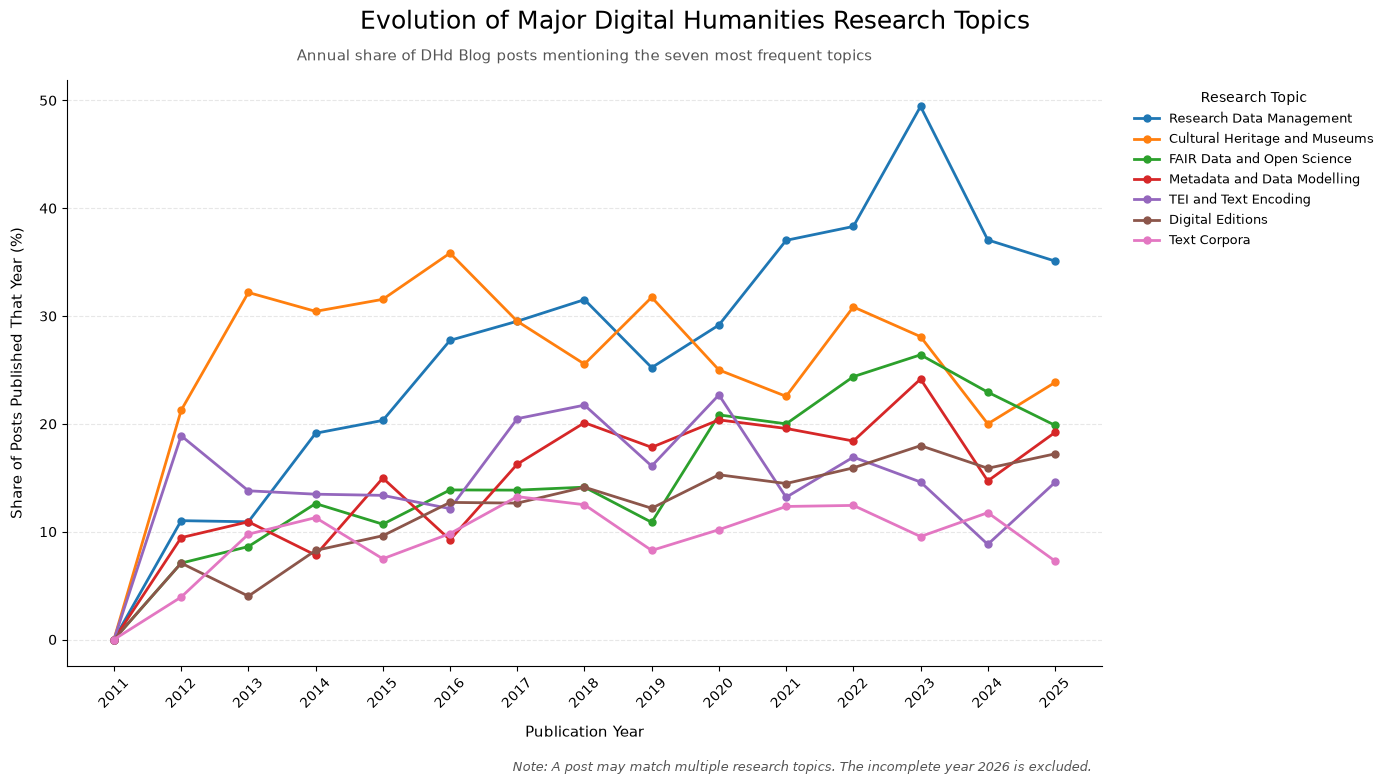

Topic counts by year:


topic,Annotation,Artificial Intelligence and LLMs,Authority Files and GND,Cultural Heritage and Museums,Data Visualization,Digital Editions,FAIR Data and Open Science,GIS and Spatial Humanities,Linked Data and Knowledge Graphs,Metadata and Data Modelling,NLP and Computational Linguistics,Network Analysis,OCR and HTR,Research Data Management,TEI and Text Encoding,Text Corpora
year,,,,,,,,,,,,,,,,
2011,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2012,7,1,3,27,7,9,9,3,10,12,4,1,1,14,24,5
2013,8,0,2,56,12,7,15,6,9,19,9,6,4,19,24,17
2014,12,4,12,70,24,19,29,6,20,18,10,3,2,44,31,26
2015,12,6,9,59,22,18,20,7,7,28,17,5,7,38,25,14
2016,9,4,7,62,23,22,24,3,13,16,15,3,3,48,21,17
2017,12,4,6,49,15,21,23,5,12,27,19,7,6,49,34,22
2018,13,9,11,47,17,26,26,21,28,37,18,5,5,58,40,23
2019,15,16,6,73,24,28,25,3,24,41,20,5,7,58,37,19


Topic shares by year (%):


topic,Annotation,Artificial Intelligence and LLMs,Authority Files and GND,Cultural Heritage and Museums,Data Visualization,Digital Editions,FAIR Data and Open Science,GIS and Spatial Humanities,Linked Data and Knowledge Graphs,Metadata and Data Modelling,NLP and Computational Linguistics,Network Analysis,OCR and HTR,Research Data Management,TEI and Text Encoding,Text Corpora
year,,,,,,,,,,,,,,,,
2011,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2012,5.5,0.8,2.4,21.3,5.5,7.1,7.1,2.4,7.9,9.4,3.1,0.8,0.8,11.0,18.9,3.9
2013,4.6,0.0,1.1,32.2,6.9,4.0,8.6,3.4,5.2,10.9,5.2,3.4,2.3,10.9,13.8,9.8
2014,5.2,1.7,5.2,30.4,10.4,8.3,12.6,2.6,8.7,7.8,4.3,1.3,0.9,19.1,13.5,11.3
2015,6.4,3.2,4.8,31.6,11.8,9.6,10.7,3.7,3.7,15.0,9.1,2.7,3.7,20.3,13.4,7.5
2016,5.2,2.3,4.0,35.8,13.3,12.7,13.9,1.7,7.5,9.2,8.7,1.7,1.7,27.7,12.1,9.8
2017,7.2,2.4,3.6,29.5,9.0,12.7,13.9,3.0,7.2,16.3,11.4,4.2,3.6,29.5,20.5,13.3
2018,7.1,4.9,6.0,25.5,9.2,14.1,14.1,11.4,15.2,20.1,9.8,2.7,2.7,31.5,21.7,12.5
2019,6.5,7.0,2.6,31.7,10.4,12.2,10.9,1.3,10.4,17.8,8.7,2.2,3.0,25.2,16.1,8.3


In [12]:
# ============================================================
# 1. DEFINE DIGITAL HUMANITIES RESEARCH TOPICS
# ============================================================

topic_keywords = {
    "Digital Editions": ["digitale edition", "digitale editionen", "digital edition", "digital editions", "scholarly edition", "scholarly editions", "editorial theory", "editionswissenschaft", "kritische edition"],
    "TEI and Text Encoding": ["tei", "text encoding initiative", "xml", "tei publisher", "exist-db", "text encoding", "markup language"],
    "Annotation": ["annotation", "annotations", "annotieren", "annotationswerkzeug", "annotationswerkzeuge", "annotation tool", "annotation tools", "webanno", "inception", "catma", "recogito"],
    "Text Corpora": ["text corpus", "text corpora", "corpus", "corpora", "korpus", "korpora", "textkorpus", "textkorpora", "corpus linguistics", "korpuslinguistik"],
    "OCR and HTR": ["ocr", "htr", "optical character recognition", "handwritten text recognition", "texterkennung", "handschriftenerkennung", "transkribus", "tesseract", "kraken", "abbyy"],
    "Research Data Management": ["research data", "research data management", "forschungsdaten", "forschungsdatenmanagement", "datenmanagement", "rdm", "data management plan", "datenmanagementplan", "repository", "repositorium", "datenrepositorium", "nfdi"],
    "FAIR Data and Open Science": ["fair data", "fair principles", "fair-prinzipien", "open science", "open data", "open access", "reproducibility", "reproduzierbarkeit"],
    "Artificial Intelligence and LLMs": ["artificial intelligence", "künstliche intelligenz", "machine learning", "maschinelles lernen", "deep learning", "neural network", "neural networks", "neuronales netz", "neuronale netze", "large language model", "large language models", "llm", "llms", "chatgpt", "generative ai", "generative künstliche intelligenz", "transformer", "transformers", "bert", "embeddings"],
    "NLP and Computational Linguistics": ["natural language processing", "nlp", "sprachverarbeitung", "computerlinguistik", "computational linguistics", "named entity recognition", "ner", "part-of-speech", "pos tagging", "sentiment analysis", "language model", "language models", "sprachmodell", "sprachmodelle", "lemmatization", "lemmatisierung", "tokenization", "tokenisierung"],
    "Linked Data and Knowledge Graphs": ["linked data", "linked open data", "lod", "rdf", "sparql", "semantic web", "knowledge graph", "knowledge graphs", "wissensgraph", "wissensgraphen", "wikidata"],
    "Authority Files and GND": ["authority file", "authority files", "normdatei", "normdateien", "normdaten", "gnd", "gemeinsame normdatei", "authority data"],
    "Metadata and Data Modelling": ["metadata", "metadaten", "data modelling", "data modeling", "datenmodellierung", "data model", "datenmodell", "ontology", "ontologies", "ontologie", "ontologien", "schema", "standardization", "standardisierung"],
    "GIS and Spatial Humanities": ["gis", "geographic information system", "geoinformationssystem", "spatial humanities", "geodaten", "mapping", "kartierung", "historical gis", "qgis", "georeferencing", "georeferenzierung", "historical maps", "historische karten"],
    "Network Analysis": ["network analysis", "netzwerkanalyse", "social network analysis", "soziale netzwerkanalyse", "graph analysis", "graphentheorie", "gephi", "network visualization", "netzwerkvisualisierung"],
    "Data Visualization": ["data visualization", "data visualisation", "datenvisualisierung", "visualization", "visualisation", "visualisierung", "dashboard", "information visualization", "informationsvisualisierung"],
    "Cultural Heritage and Museums": ["cultural heritage", "kulturerbe", "museum", "museums", "archive", "archives", "archiv", "bibliothek", "bibliotheken", "library", "libraries", "digital cultural heritage"]
}

# ============================================================
# 2. PREPARE SEARCHABLE TEXT
# ============================================================

topic_df = analysis_df.copy()

topic_df["year"] = pd.to_numeric(
    topic_df["year"],
    errors="coerce"
)

for column in ["title", "categories", "tags", "text"]:
    if column not in topic_df.columns:
        topic_df[column] = ""

    topic_df[column] = (
        topic_df[column]
        .fillna("")
        .astype(str)
    )

topic_df["search_text"] = (
    topic_df["title"] + " " +
    topic_df["categories"] + " " +
    topic_df["tags"] + " " +
    topic_df["text"]
).str.lower()

# ============================================================
# 3. CREATE TOPIC FLAGS
# ============================================================

for topic, keywords in topic_keywords.items():

    pattern = "|".join(
        rf"(?<!\w){re.escape(keyword.lower())}(?!\w)"
        for keyword in keywords
    )

    topic_df[topic] = topic_df["search_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

# ============================================================
# 4. OVERALL TOPIC FREQUENCY
# ============================================================

topic_summary_rows = []

total_posts = len(topic_df)

for topic in topic_keywords:

    topic_posts = int(topic_df[topic].sum())

    topic_summary_rows.append({
        "topic": topic,
        "posts": topic_posts,
        "percentage_of_all_posts": (
            topic_posts / total_posts * 100
            if total_posts > 0
            else 0
        )
    })

topic_summary = (
    pd.DataFrame(topic_summary_rows)
    .sort_values(
        "posts",
        ascending=False
    )
    .reset_index(drop=True)
)

display(topic_summary)

# ============================================================
# 5. FIGURE 1 — MOST FREQUENTLY DISCUSSED TOPICS
# ============================================================

ranked_topics = (
    topic_summary
    .sort_values("posts")
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    ranked_topics["topic"],
    ranked_topics["posts"],
    height=0.65
)

# Highlight most frequent topic
bars[-1].set_color("tab:orange")

for bar, posts, percentage in zip(
    bars,
    ranked_topics["posts"],
    ranked_topics["percentage_of_all_posts"]
):
    ax.annotate(
        f"{int(posts)} ({percentage:.1f}%)",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.18",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Frequently Discussed Digital Humanities Research Topics",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_title(
    "Number and share of DHd Blog posts mentioning each topic",
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Number of Blog Posts",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.set_xlim(
    0,
    ranked_topics["posts"].max() * 1.25
)

ax.text(
    0.99,
    -0.08,
    (
        "Note: A post may match more than one topic. "
        "Topics are identified using predefined German and English keyword groups."
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig11_most_frequent_dh_research_topics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. TOPIC COUNTS BY YEAR
# ============================================================

valid_years = sorted(
    topic_df["year"]
    .dropna()
    .astype(int)
    .unique()
)

yearly_post_totals = (
    topic_df
    .dropna(subset=["year"])
    .groupby("year")
    .size()
    .rename("total_posts")
)

topic_year_rows = []

for topic in topic_keywords:

    yearly_topic_counts = (
        topic_df.loc[topic_df[topic]]
        .groupby("year")
        .size()
    )

    for year in valid_years:

        topic_posts = int(
            yearly_topic_counts.get(year, 0)
        )

        year_total = int(
            yearly_post_totals.get(year, 0)
        )

        topic_year_rows.append({
            "year": int(year),
            "topic": topic,
            "posts": topic_posts,
            "share_of_yearly_posts": (
                topic_posts / year_total * 100
                if year_total > 0
                else 0
            )
        })

topic_year_df = pd.DataFrame(topic_year_rows)

# Exclude incomplete 2026 from trend chart
trend_df = topic_year_df[
    topic_year_df["year"] < 2026
].copy()

# Use most frequent topics only for readability
TOP_N = 7

selected_topics = (
    topic_summary
    .head(TOP_N)["topic"]
    .tolist()
)

trend_df = trend_df[
    trend_df["topic"].isin(selected_topics)
]

# ============================================================
# 7. FIGURE 2 — TOPIC TRENDS OVER TIME
# ============================================================

fig, ax = plt.subplots(figsize=(14, 8))

for topic in selected_topics:

    topic_data = (
        trend_df[
            trend_df["topic"] == topic
        ]
        .sort_values("year")
    )

    ax.plot(
        topic_data["year"],
        topic_data["share_of_yearly_posts"],
        marker="o",
        markersize=5,
        linewidth=2,
        label=topic
    )

fig.suptitle(
    "Evolution of Major Digital Humanities Research Topics",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_title(
    "Annual share of DHd Blog posts mentioning the seven most frequent topics",
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Publication Year",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Share of Posts Published That Year (%)",
    fontsize=11,
    labelpad=10
)

ax.set_xticks(
    sorted(trend_df["year"].unique())
)

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Research Topic",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

ax.text(
    0.99,
    -0.16,
    (
        "Note: A post may match multiple research topics. "
        "The incomplete year 2026 is excluded."
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "fig12_dh_research_topic_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. DISPLAY YEARLY COUNTS AND SHARES
# ============================================================

topic_count_table = (
    topic_year_df
    .pivot(
        index="year",
        columns="topic",
        values="posts"
    )
    .fillna(0)
    .astype(int)
)

topic_share_table = (
    topic_year_df
    .pivot(
        index="year",
        columns="topic",
        values="share_of_yearly_posts"
    )
    .fillna(0)
    .round(1)
)

print("Topic counts by year:")
display(topic_count_table)

print("Topic shares by year (%):")
display(topic_share_table)


## 11. Longest Most Commented Post

In [28]:
# ============================================================
# EXTREME POSTS — PUBLICATION-STYLE TABLE
# ============================================================

extremes = []

# Detect the correct comments column
comments_column = None

if "comments" in analysis_df.columns:
    comments_column = "comments"
elif "comment_count" in analysis_df.columns:
    comments_column = "comment_count"


# ------------------------------------------------------------
# Longest post
# ------------------------------------------------------------

if "word_count" in analysis_df.columns:

    longest = analysis_df.loc[
        analysis_df["word_count"].idxmax()
    ]

    extremes.append({
        "Record": "Longest post",
        "Title": longest["title"],
        "Date": longest["publication_date"],
        "Author": longest["author"],
        "Value": f"{int(longest['word_count']):,} words",
        "URL": longest.get("url", "")
    })


# ------------------------------------------------------------
# Shortest meaningful post
# Excludes zero-word or nearly empty posts
# ------------------------------------------------------------

if "word_count" in analysis_df.columns:

    meaningful_posts = analysis_df[
        analysis_df["word_count"] >= 20
    ]

    if not meaningful_posts.empty:

        shortest = meaningful_posts.loc[
            meaningful_posts["word_count"].idxmin()
        ]

        extremes.append({
            "Record": "Shortest post",
            "Title": shortest["title"],
            "Date": shortest["publication_date"],
            "Author": shortest["author"],
            "Value": f"{int(shortest['word_count']):,} words",
            "URL": shortest.get("url", "")
        })


# ------------------------------------------------------------
# Most commented post
# ------------------------------------------------------------

if comments_column is not None:

    most_comments = analysis_df.loc[
        analysis_df[comments_column].idxmax()
    ]

    extremes.append({
        "Record": "Most commented post",
        "Title": most_comments["title"],
        "Date": most_comments["publication_date"],
        "Author": most_comments["author"],
        "Value": (
            f"{int(most_comments[comments_column]):,} comments"
        ),
        "URL": most_comments.get("url", "")
    })


# ------------------------------------------------------------
# Most tagged post
# ------------------------------------------------------------

if "tags" in analysis_df.columns:

    tag_number = (
        analysis_df["tags"]
        .fillna("")
        .str.split(r"\s*\|\s*")
        .apply(
            lambda values:
            len({
                value.strip()
                for value in values
                if value.strip()
            })
        )
    )

    most_tags = analysis_df.loc[
        tag_number.idxmax()
    ]

    extremes.append({
        "Record": "Most tagged post",
        "Title": most_tags["title"],
        "Date": most_tags["publication_date"],
        "Author": most_tags["author"],
        "Value": f"{int(tag_number.max())} tags",
        "URL": most_tags.get("url", "")
    })


# ------------------------------------------------------------
# Most categorized post
# ------------------------------------------------------------

if "categories" in analysis_df.columns:

    category_number = (
        analysis_df["categories"]
        .fillna("")
        .str.split(r"\s*\|\s*")
        .apply(
            lambda values:
            len({
                value.strip()
                for value in values
                if value.strip()
            })
        )
    )

    most_categories = analysis_df.loc[
        category_number.idxmax()
    ]

    extremes.append({
        "Record": "Most categorized post",
        "Title": most_categories["title"],
        "Date": most_categories["publication_date"],
        "Author": most_categories["author"],
        "Value": f"{int(category_number.max())} categories",
        "URL": most_categories.get("url", "")
    })


# ============================================================
# PREPARE TABLE
# ============================================================

extremes_df = pd.DataFrame(extremes)

extremes_df["Date"] = pd.to_datetime(
    extremes_df["Date"],
    errors="coerce"
).dt.strftime("%d %b %Y")

# Keep titles readable
extremes_df["Title"] = extremes_df["Title"].fillna("")
extremes_df["Author"] = extremes_df["Author"].fillna("Unknown")


# ============================================================
# STYLE TABLE
# ============================================================

styled_extremes = (
    extremes_df[
        ["Record", "Title", "Date", "Author", "Value", "URL"]
    ]
    .style
    .hide(axis="index")
    .set_caption("DHd Blog Records and Extreme Values")
    .set_properties(
        subset=["Record"],
        **{
            "font-weight": "600",
            "white-space": "nowrap"
        }
    )
    .set_properties(
        subset=["Title"],
        **{
            "text-align": "left",
            "max-width": "420px",
            "white-space": "normal"
        }
    )
    .set_properties(
        subset=["Date", "Author", "Value"],
        **{
            "white-space": "nowrap"
        }
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "18px"),
                ("font-weight", "400"),
                ("text-align", "left"),
                ("padding-bottom", "14px"),
                ("color", "#222222")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#eeeeee"),
                ("color", "#222222"),
                ("font-weight", "600"),
                ("text-align", "left"),
                ("padding", "10px"),
                ("border-bottom", "1px solid #cccccc")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px"),
                ("border-bottom", "1px solid #e5e5e5"),
                ("vertical-align", "top")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [
                ("background-color", "#f8f8f8")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("font-family", "DejaVu Sans, Arial, sans-serif"),
                ("font-size", "13px")
            ]
        }
    ])
)

display(styled_extremes)


Record,Title,Date,Author,Value,URL
Longest post,Die digitale Erfassung von mittelalterlichen Rechtsgeschäften – Beschreibung der semistrukturierten XML-Datenbank db_for_medieval_legal_transactions,31 Oct 2021,Korbinian Grünwald,"6,022 words",https://dhd-blog.org/?p=16737
Shortest post,DFG Stelle für eine/n Wissenschaftsmanagerin / Wissenschaftsmanager,13 Mar 2018,Hubert Mara,22 words,https://dhd-blog.org/?p=9498
Most commented post,Manifest für digitale Editionen,11 Mar 2022,Christiane Fritze,72 comments,https://dhd-blog.org/?p=17563
Most tagged post,"Stellenausschreibung für Stud. Hilfskraft (80 oder 2×40 MoStd.), Research Area 5 des Exzellenzclusters „Temporal Communities“, FU Berlin",15 Jun 2022,Bart Soethaert,21 tags,https://dhd-blog.org/?p=18031
Most categorized post,"Einladung zum virtuellen Digital-Humanities-Kolloquium der BBAW, 3. Juli 2020",18 Jun 2020,Christian Thomas,12 categories,https://dhd-blog.org/?p=13911


## 12. Most Frequent Words and Word Cloud

,word,frequency
3,universität,2705
147,sowie,2433
91,digitalen,2430
32,digitale,2184
248,data,1976
353,innen,1941
607,daten,1765
11200,dariah,1676
986,berlin,1651
292,research,1543


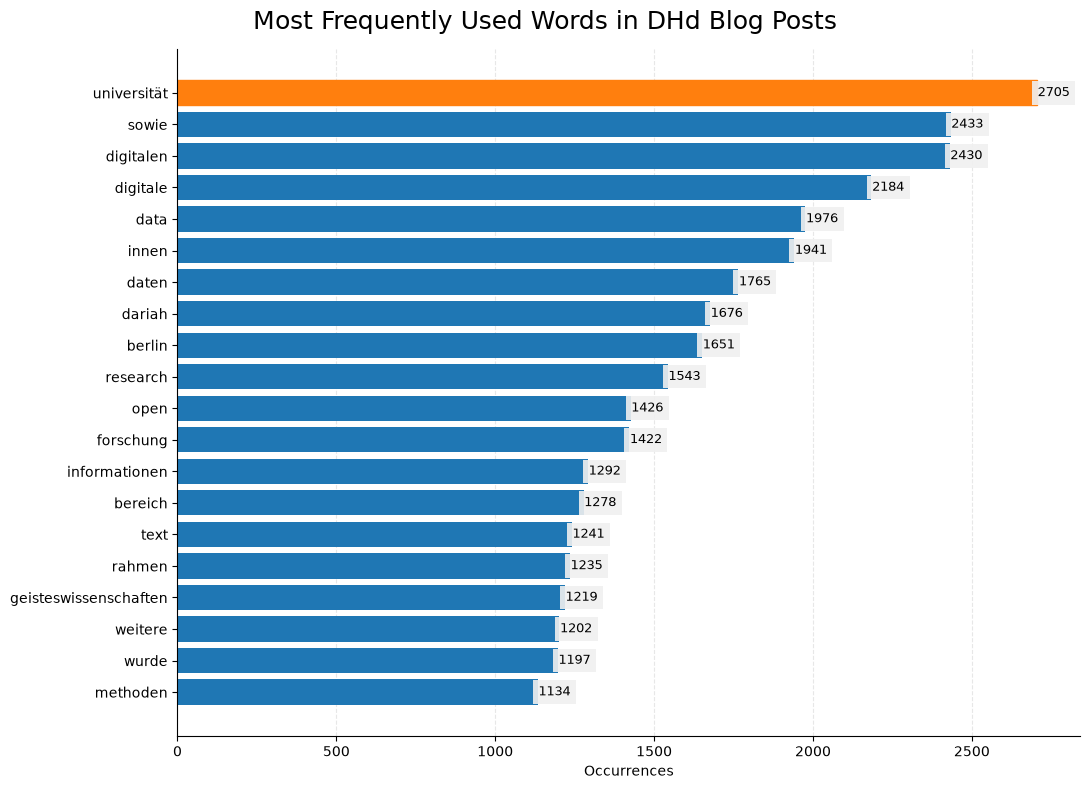

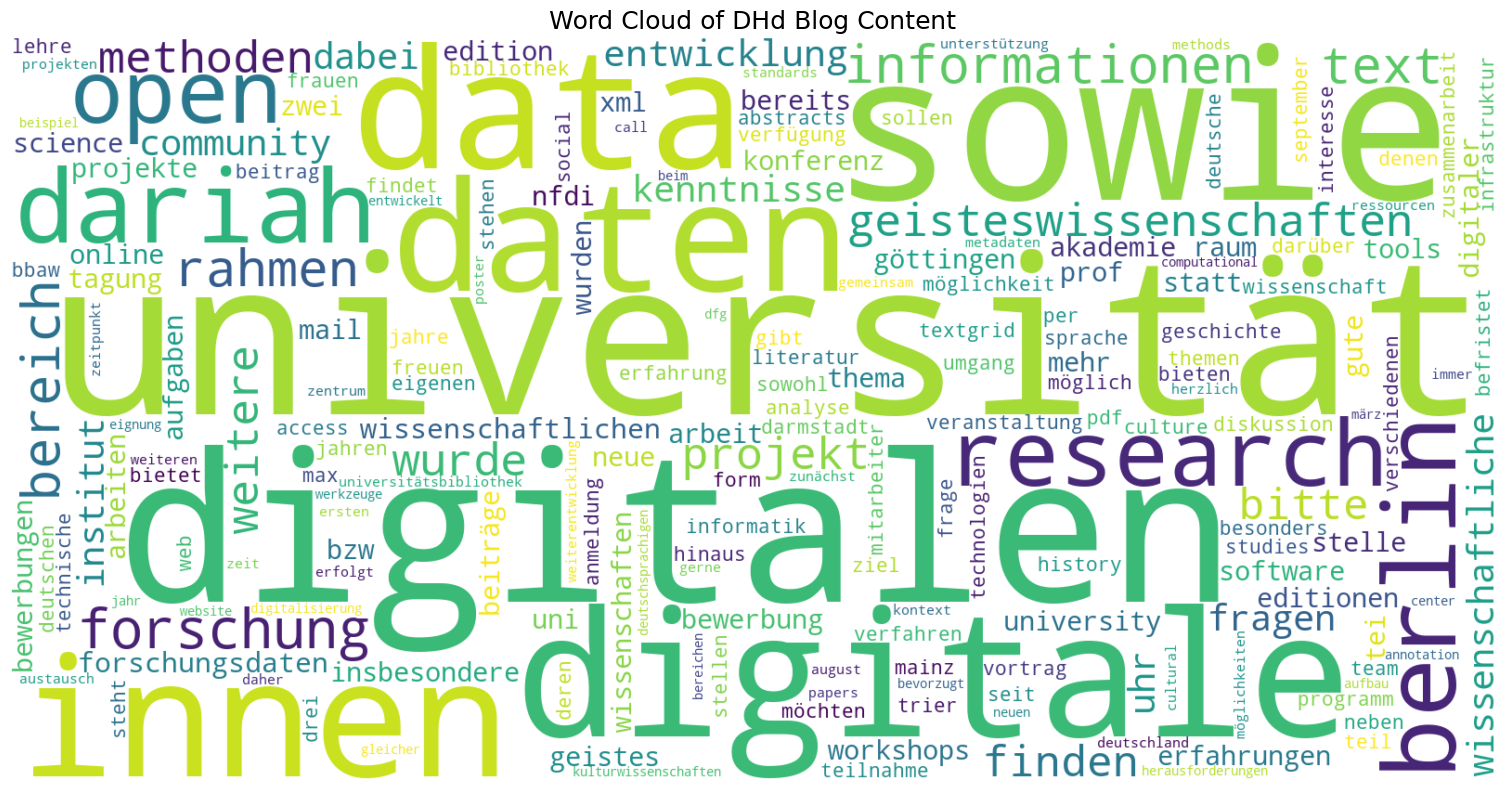

In [26]:
# ============================================================
# CLEAN TEXT + MOST FREQUENT WORDS + WORD CLOUD
# ============================================================





try:
    stopwords.words("german")
except LookupError:
    nltk.download("stopwords", quiet=True)

# ------------------------------------------------------------
# Combine all blog text
# ------------------------------------------------------------

text = (
    analysis_df["text"]
    .fillna("")
    .str.lower()
    .str.cat(sep=" ")
)

# ------------------------------------------------------------
# Remove URLs
# ------------------------------------------------------------

text = re.sub(r"http\S+", " ", text)

# ------------------------------------------------------------
# Remove HTML
# ------------------------------------------------------------

text = re.sub(r"<.*?>", " ", text)

# ------------------------------------------------------------
# Keep letters only
# ------------------------------------------------------------

text = re.sub(r"[^a-zA-ZäöüÄÖÜß ]", " ", text)

# ------------------------------------------------------------
# Tokenize
# ------------------------------------------------------------

words = text.split()

# ------------------------------------------------------------
# Stopwords
# ------------------------------------------------------------

stop_words = set(stopwords.words("english"))
stop_words.update(stopwords.words("german"))

# ------------------------------------------------------------
# Add custom stopwords
# ------------------------------------------------------------

custom_stopwords = {
    "dhd",
    "blog",
    "digital",
    "humanities",
    "https",
    "www",
    "org",
    "de",
    "com",
    "amp",
    "nbsp",
    "post",
    "posts",
    "information",
    "please",
    "using",
    "also",
    "one",
    "new",
    "can",
    "will",
    "may",
    "many",
    "within",
    "among",
    "based",
    "work",
    "project",
    "projects",
    "event",
    "events",
    "conference",
    "workshop"
}

stop_words.update(custom_stopwords)

# ------------------------------------------------------------
# Keep meaningful words
# ------------------------------------------------------------

clean_words = [
    word
    for word in words
    if (
        len(word) > 2
        and word not in stop_words
    )
]

# ------------------------------------------------------------
# Word frequencies
# ------------------------------------------------------------

word_counts = Counter(clean_words)

freq_df = (
    pd.DataFrame(
        word_counts.items(),
        columns=["word", "frequency"]
    )
    .sort_values(
        "frequency",
        ascending=False
    )
)

display(freq_df.head(30))

# ------------------------------------------------------------
# Horizontal bar chart
# ------------------------------------------------------------

top_words = (
    freq_df
    .head(20)
    .sort_values("frequency")
)

fig, ax = plt.subplots(figsize=(11,8))

bars = ax.barh(
    top_words["word"],
    top_words["frequency"]
)

bars[-1].set_color("tab:orange")

for bar in bars:

    ax.text(
        bar.get_width()+2,
        bar.get_y()+bar.get_height()/2,
        int(bar.get_width()),
        va="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

fig.suptitle(
    "Most Frequently Used Words in DHd Blog Posts",
    fontsize=18,
    fontweight="normal"
)

ax.set_xlabel("Occurrences")
ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# Word cloud
# ------------------------------------------------------------

wordcloud = WordCloud(
    width=1600,
    height=800,
    background_color="white",
    max_words=200,
    collocations=False
).generate_from_frequencies(word_counts)

plt.figure(figsize=(16,8))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Word Cloud of DHd Blog Content",
    fontsize=18
)

plt.tight_layout()

plt.show()


## 13. Category by Month Heatmap

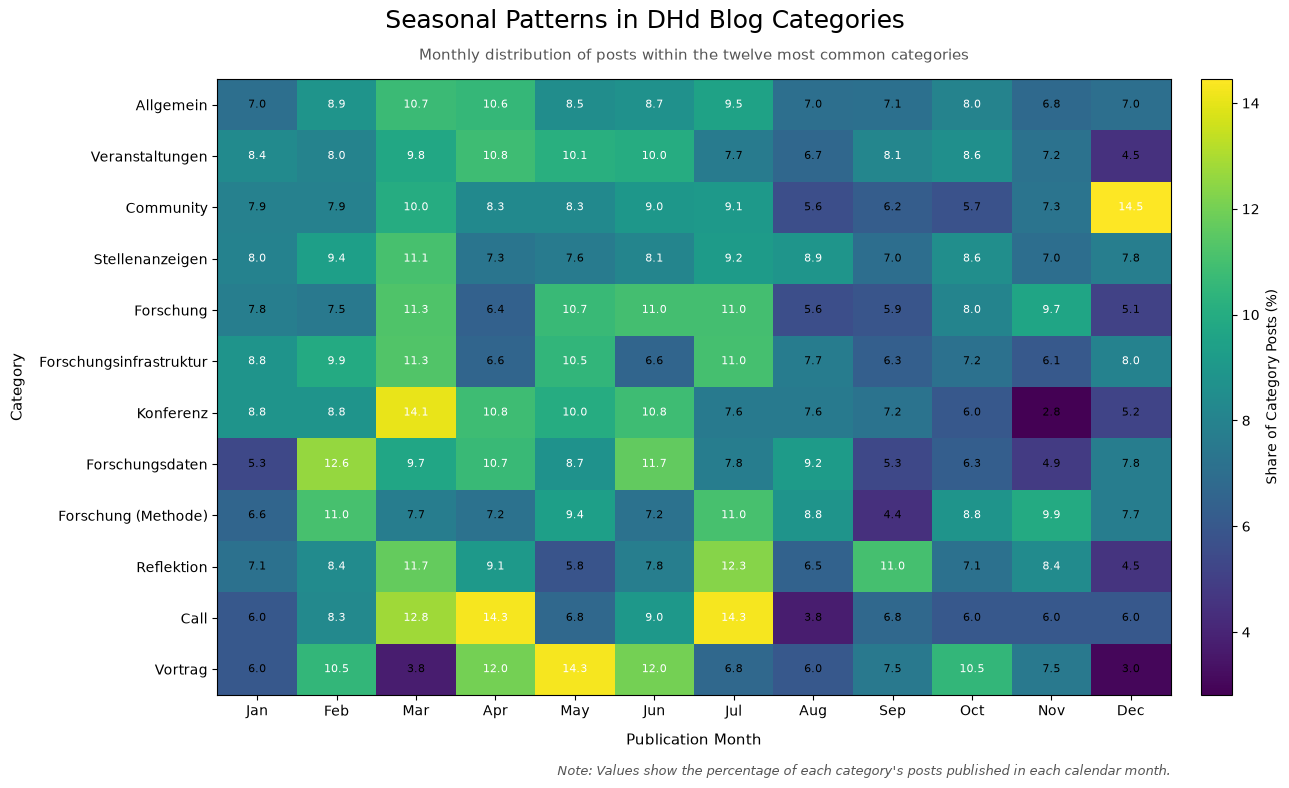

In [24]:
# ============================================================
# CATEGORY × MONTH HEATMAP
# ============================================================

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

category_month_df = (
    analysis_df[
        ["post_id", "month", "categories"]
    ]
    .copy()
)

category_month_df["categories"] = (
    category_month_df["categories"]
    .fillna("")
    .astype(str)
)

category_month_df = (
    category_month_df
    .assign(
        category=lambda data:
        data["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_month_df["category"] = (
    category_month_df["category"]
    .fillna("")
    .str.strip()
)

category_month_df = category_month_df[
    category_month_df["category"].ne("")
].copy()

category_month_df["month"] = pd.to_numeric(
    category_month_df["month"],
    errors="coerce"
)

category_month_df = category_month_df.dropna(
    subset=["month"]
)

category_month_df["month"] = (
    category_month_df["month"].astype(int)
)

# Count each post once per category
category_month_df = category_month_df.drop_duplicates(
    subset=["post_id", "category"]
)

# Keep top 12 categories
top_categories = (
    category_month_df["category"]
    .value_counts()
    .head(12)
    .index
)

category_month_df = category_month_df[
    category_month_df["category"].isin(top_categories)
]

# Raw counts
category_month_counts = (
    category_month_df
    .groupby(["category", "month"])["post_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

# Convert each row to percentages
category_month_share = (
    category_month_counts
    .div(category_month_counts.sum(axis=1), axis=0)
    .mul(100)
)

# Sort categories by overall frequency
category_order = (
    category_month_counts
    .sum(axis=1)
    .sort_values(ascending=False)
    .index
)

category_month_share = category_month_share.loc[
    category_order
]

# Plot
fig, ax = plt.subplots(figsize=(13, 8))

image = ax.imshow(
    category_month_share.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels, fontsize=10)

ax.set_yticks(
    np.arange(len(category_month_share.index))
)

ax.set_yticklabels(
    category_month_share.index,
    fontsize=10
)

# Add values
max_value = category_month_share.values.max()

for row in range(category_month_share.shape[0]):
    for column in range(category_month_share.shape[1]):

        value = category_month_share.iloc[row, column]

        text_color = (
            "white"
            if max_value > 0 and value > max_value * 0.55
            else "black"
        )

        ax.text(
            column,
            row,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=8,
            color=text_color
        )

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

colorbar.set_label(
    "Share of Category Posts (%)",
    fontsize=10
)

fig.suptitle(
    "Seasonal Patterns in DHd Blog Categories",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    "Monthly distribution of posts within the twelve most common categories",
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Publication Month",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Category",
    fontsize=11,
    labelpad=10
)

ax.text(
    1.0,
    -0.13,
    (
        "Note: Values show the percentage of each category's posts "
        "published in each calendar month."
    ),
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "category_by_month_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 14. Post Length × Category Boxplot

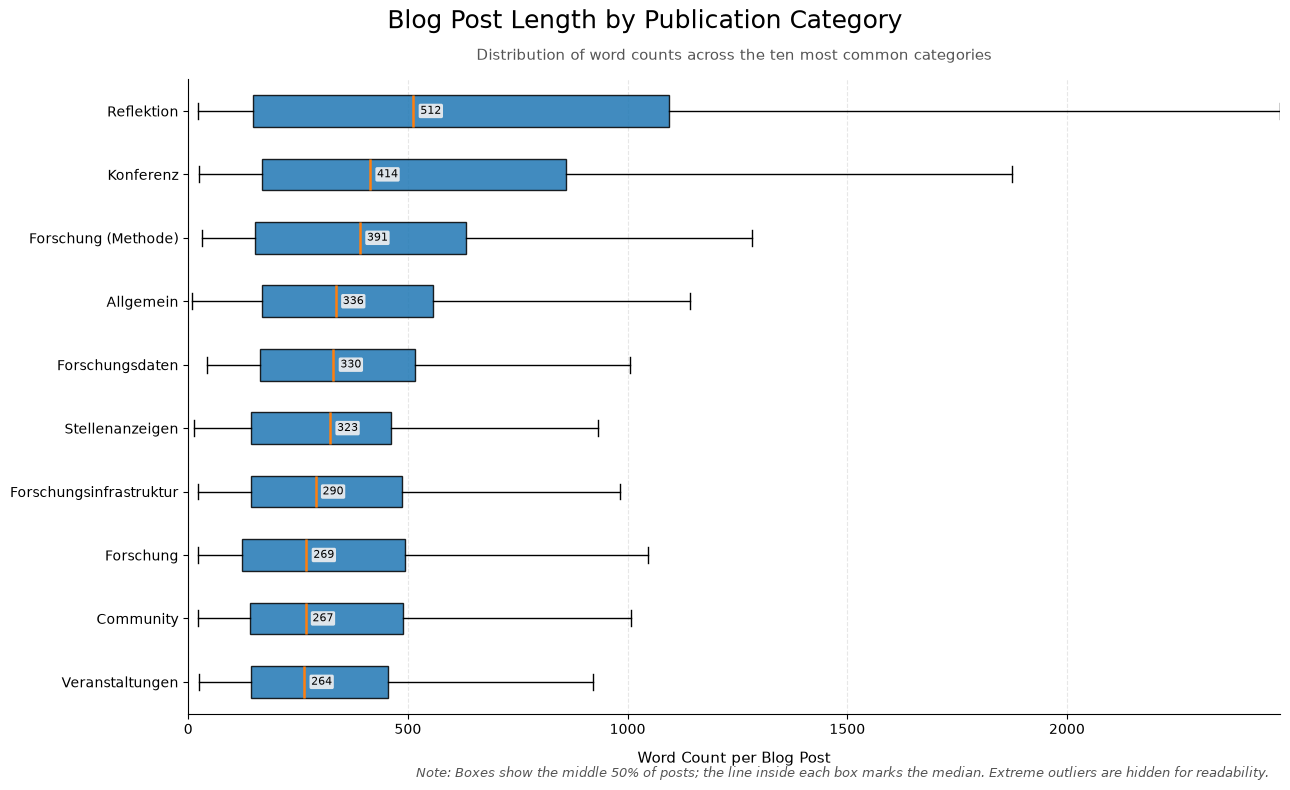

,posts,mean_words,median_words,minimum_words,maximum_words
category,,,,,
Reflektion,154,769.0,512.5,23,4393
Konferenz,249,649.8,414.0,25,4393
Forschung (Methode),181,555.9,391.0,31,6022
Allgemein,1220,462.5,336.0,8,4690
Forschungsdaten,206,498.4,330.5,43,4690
Stellenanzeigen,641,340.2,323.0,13,4171
Forschungsinfrastruktur,363,444.1,290.0,22,4690
Forschung,373,435.8,269.0,22,6022
Community,768,442.9,267.0,22,4690


In [29]:
# ============================================================
# POST LENGTH × CATEGORY BOXPLOT
# ============================================================

category_length_df = (
    analysis_df[
        ["post_id", "categories", "word_count"]
    ]
    .copy()
)

category_length_df["word_count"] = pd.to_numeric(
    category_length_df["word_count"],
    errors="coerce"
)

category_length_df["categories"] = (
    category_length_df["categories"]
    .fillna("")
    .astype(str)
)

category_length_df = (
    category_length_df
    .assign(
        category=lambda data:
        data["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_length_df["category"] = (
    category_length_df["category"]
    .fillna("")
    .str.strip()
)

category_length_df = category_length_df[
    category_length_df["category"].ne("")
].dropna(
    subset=["word_count"]
)

category_length_df = category_length_df[
    category_length_df["word_count"] > 0
].copy()

# Count each post once per category
category_length_df = category_length_df.drop_duplicates(
    subset=["post_id", "category"]
)

# Keep top 10 categories by number of posts
top_categories = (
    category_length_df["category"]
    .value_counts()
    .head(10)
    .index
)

plot_df = category_length_df[
    category_length_df["category"].isin(top_categories)
].copy()

# Order categories by median word count
category_order = (
    plot_df
    .groupby("category")["word_count"]
    .median()
    .sort_values()
    .index
)

box_data = [
    plot_df.loc[
        plot_df["category"] == category,
        "word_count"
    ].values
    for category in category_order
]

fig, ax = plt.subplots(figsize=(13, 8))

boxplot = ax.boxplot(
    box_data,
    orientation="horizontal",
    tick_labels=category_order,
    patch_artist=True,
    showfliers=False,
    medianprops={
        "linewidth": 1.8
    },
    boxprops={
        "alpha": 0.85
    },
    whiskerprops={
        "linewidth": 1
    },
    capprops={
        "linewidth": 1
    }
)

# Add median labels
for position, category in enumerate(
    category_order,
    start=1
):
    median_value = (
        plot_df.loc[
            plot_df["category"] == category,
            "word_count"
        ]
        .median()
    )

    ax.annotate(
        f"{median_value:.0f}",
        xy=(median_value, position),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.15",
            facecolor="#f0f0f0",
            edgecolor="none",
            alpha=0.9
        )
    )

# Limit display to 99th percentile
display_limit = plot_df["word_count"].quantile(0.99)

ax.set_xlim(
    0,
    display_limit
)

fig.suptitle(
    "Blog Post Length by Publication Category",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    "Distribution of word counts across the ten most common categories",
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Word Count per Blog Post",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.text(
    0.99,
    -0.10,
    (
        "Note: Boxes show the middle 50% of posts; the line inside each "
        "box marks the median. Extreme outliers are hidden for readability."
    ),
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "word_count_by_category_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Supporting summary table
category_length_summary = (
    plot_df
    .groupby("category")["word_count"]
    .agg(
        posts="count",
        mean_words="mean",
        median_words="median",
        minimum_words="min",
        maximum_words="max"
    )
    .round(1)
    .sort_values(
        "median_words",
        ascending=False
    )
)

display(category_length_summary)


## 15. Category × Tag Relationship Heatmap

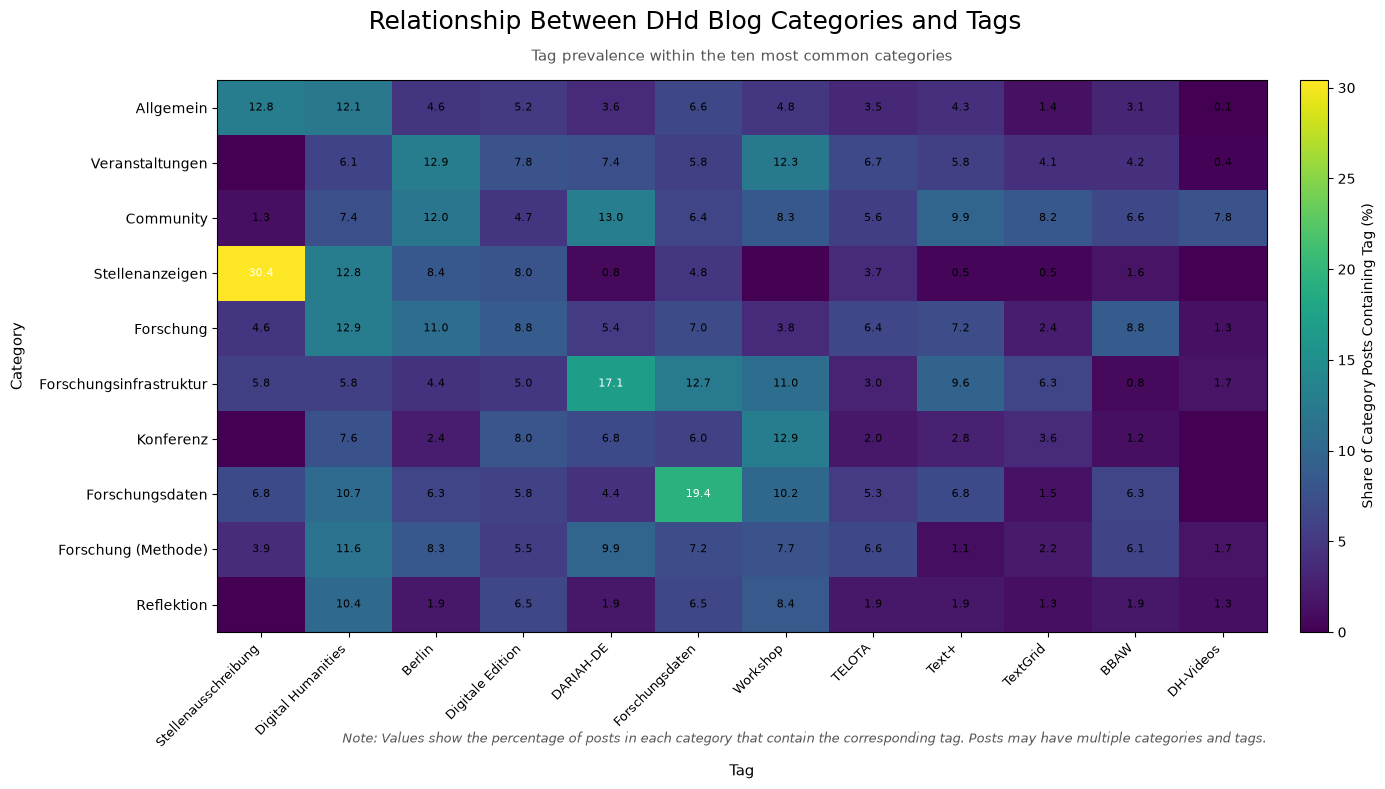

In [22]:
# ============================================================
# CATEGORY × TAG RELATIONSHIP HEATMAP
# ============================================================

relationship_df = analysis_df[
    ["post_id", "categories", "tags"]
].copy()

for column in ["categories", "tags"]:
    relationship_df[column] = (
        relationship_df[column]
        .fillna("")
        .astype(str)
    )

# Create category rows
category_rows = (
    relationship_df[
        ["post_id", "categories"]
    ]
    .assign(
        category=lambda data:
        data["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_rows["category"] = (
    category_rows["category"]
    .fillna("")
    .str.strip()
)

category_rows = category_rows[
    category_rows["category"].ne("")
].drop_duplicates(
    subset=["post_id", "category"]
)

# Create tag rows
tag_rows = (
    relationship_df[
        ["post_id", "tags"]
    ]
    .assign(
        tag=lambda data:
        data["tags"].str.split(r"\s*\|\s*")
    )
    .explode("tag")
)

tag_rows["tag"] = (
    tag_rows["tag"]
    .fillna("")
    .str.strip()
)

tag_rows = tag_rows[
    tag_rows["tag"].ne("")
].drop_duplicates(
    subset=["post_id", "tag"]
)

# Select top categories and tags
top_categories = (
    category_rows["category"]
    .value_counts()
    .head(10)
    .index
)

top_tags = (
    tag_rows["tag"]
    .value_counts()
    .head(12)
    .index
)

category_rows = category_rows[
    category_rows["category"].isin(top_categories)
]

tag_rows = tag_rows[
    tag_rows["tag"].isin(top_tags)
]

# Join categories and tags through post ID
category_tag_pairs = category_rows.merge(
    tag_rows,
    on="post_id",
    how="inner"
)

# Number of posts in every category
category_totals = (
    category_rows
    .groupby("category")["post_id"]
    .nunique()
)

# Number of posts containing each category-tag pair
category_tag_counts = (
    category_tag_pairs
    .groupby(["category", "tag"])["post_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(
        index=top_categories,
        columns=top_tags,
        fill_value=0
    )
)

# Convert to percentage within category
category_tag_share = (
    category_tag_counts
    .div(category_totals, axis=0)
    .mul(100)
)

# Sort categories by overall count
category_order = (
    category_totals
    .sort_values(ascending=False)
    .index
)

category_tag_share = category_tag_share.loc[
    category_order
]

fig, ax = plt.subplots(figsize=(14, 8))

image = ax.imshow(
    category_tag_share.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(category_tag_share.columns))
)

ax.set_xticklabels(
    category_tag_share.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(category_tag_share.index))
)

ax.set_yticklabels(
    category_tag_share.index,
    fontsize=10
)

maximum_value = category_tag_share.values.max()

for row in range(category_tag_share.shape[0]):
    for column in range(category_tag_share.shape[1]):

        value = category_tag_share.iloc[row, column]

        if value > 0:

            text_color = (
                "white"
                if maximum_value > 0
                and value > maximum_value * 0.55
                else "black"
            )

            ax.text(
                column,
                row,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                color=text_color
            )

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

colorbar.set_label(
    "Share of Category Posts Containing Tag (%)",
    fontsize=10
)

fig.suptitle(
    "Relationship Between DHd Blog Categories and Tags",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    "Tag prevalence within the ten most common categories",
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Tag",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Category",
    fontsize=11,
    labelpad=10
)

ax.text(
    1.0,
    -0.20,
    (
        "Note: Values show the percentage of posts in each category "
        "that contain the corresponding tag. Posts may have multiple "
        "categories and tags."
    ),
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "category_tag_relationship_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 16. Category Co-occurence heatmap

Categories selected for the heatmap:
['Community', 'Veranstaltungen', 'Allgemein', 'Stellenanzeigen', 'Forschungsinfrastruktur', 'Konferenz', 'Forschung', 'Forschungsdaten', 'Vortrag']


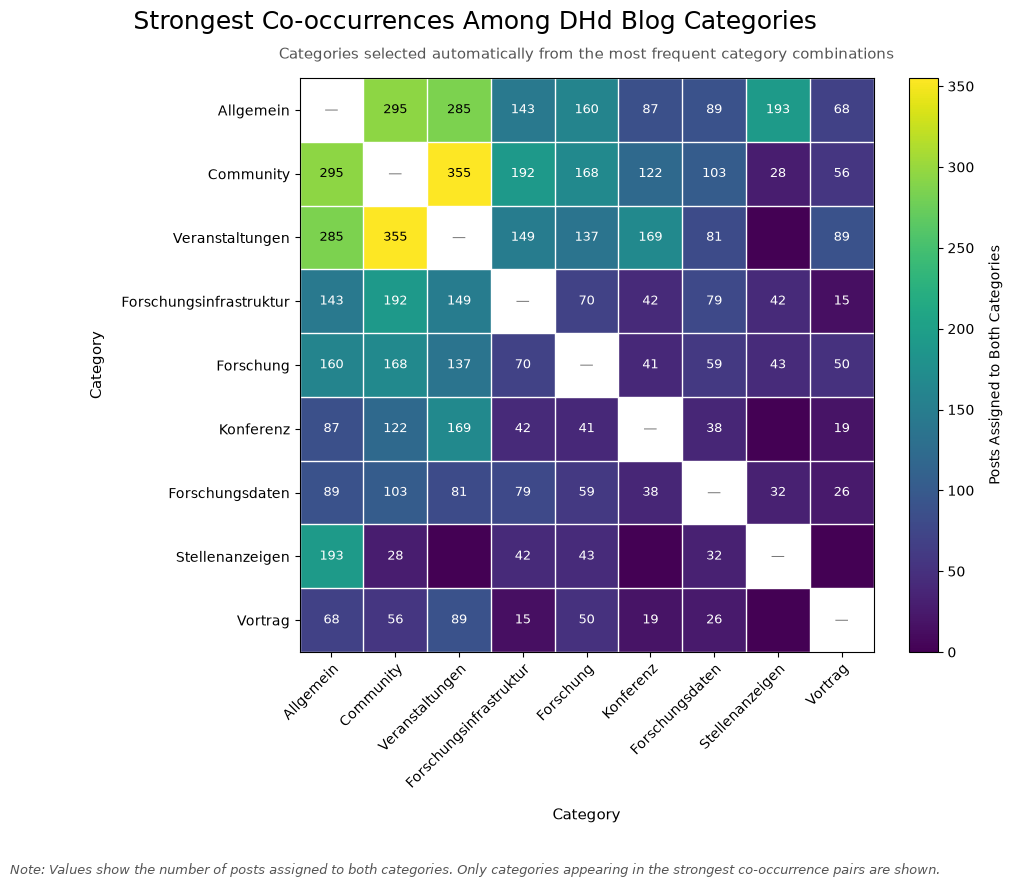

category_1,category_2,cooccurring_posts
Community,Veranstaltungen,355
Allgemein,Community,295
Allgemein,Veranstaltungen,285
Allgemein,Stellenanzeigen,193
Community,Forschungsinfrastruktur,192
Konferenz,Veranstaltungen,169
Community,Forschung,168
Allgemein,Forschung,160
Forschungsinfrastruktur,Veranstaltungen,149
Allgemein,Forschungsinfrastruktur,143


In [30]:
# ============================================================
# 1. CLEAN AND SPLIT CATEGORIES
# ============================================================

category_lists = (
    analysis_df["categories"]
    .fillna("")
    .astype(str)
    .str.split(r"\s*\|\s*")
)

clean_category_lists = []

for categories in category_lists:

    cleaned = sorted({
        category.strip()
        for category in categories
        if category.strip()
    })

    clean_category_lists.append(cleaned)


# ============================================================
# 2. COUNT CATEGORY PAIRS
# ============================================================

pair_counts = Counter()

for categories in clean_category_lists:

    for category_1, category_2 in combinations(categories, 2):
        pair_counts[(category_1, category_2)] += 1


pair_df = pd.DataFrame(
    [
        {
            "category_1": category_1,
            "category_2": category_2,
            "cooccurring_posts": count
        }
        for (category_1, category_2), count in pair_counts.items()
    ]
)

if pair_df.empty:
    raise ValueError(
        "No category co-occurrences were found. "
        "Check how categories are separated in the dataset."
    )

pair_df = (
    pair_df
    .sort_values(
        "cooccurring_posts",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 3. SELECT CATEGORIES FROM THE STRONGEST RELATIONSHIPS
# ============================================================

TOP_PAIRS = 15
MAX_CATEGORIES = 10

strongest_pairs = pair_df.head(TOP_PAIRS)

selected_categories = []

for _, row in strongest_pairs.iterrows():

    for category in [
        row["category_1"],
        row["category_2"]
    ]:

        if category not in selected_categories:
            selected_categories.append(category)

    if len(selected_categories) >= MAX_CATEGORIES:
        break

selected_categories = selected_categories[:MAX_CATEGORIES]

print("Categories selected for the heatmap:")
print(selected_categories)


# ============================================================
# 4. CREATE CO-OCCURRENCE MATRIX
# ============================================================

cooccurrence_matrix = pd.DataFrame(
    0,
    index=selected_categories,
    columns=selected_categories,
    dtype=int
)

for _, row in pair_df.iterrows():

    category_1 = row["category_1"]
    category_2 = row["category_2"]
    count = int(row["cooccurring_posts"])

    if (
        category_1 in selected_categories
        and category_2 in selected_categories
    ):

        cooccurrence_matrix.loc[
            category_1,
            category_2
        ] = count

        cooccurrence_matrix.loc[
            category_2,
            category_1
        ] = count


# Keep diagonal empty because the chart focuses on relationships
display_matrix = cooccurrence_matrix.astype(float).copy()

for category in selected_categories:
    display_matrix.loc[
        category,
        category
    ] = np.nan


# Order categories by total relationship strength
category_strength = (
    cooccurrence_matrix
    .sum(axis=1)
    .sort_values(ascending=False)
)

category_order = category_strength.index.tolist()

display_matrix = display_matrix.loc[
    category_order,
    category_order
]

cooccurrence_matrix = cooccurrence_matrix.loc[
    category_order,
    category_order
]


# ============================================================
# 5. DRAW HEATMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

masked_values = np.ma.masked_invalid(
    display_matrix.to_numpy()
)

image = ax.imshow(
    masked_values,
    aspect="equal",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(category_order))
)

ax.set_xticklabels(
    category_order,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)

ax.set_yticks(
    np.arange(len(category_order))
)

ax.set_yticklabels(
    category_order,
    fontsize=10
)

maximum_value = np.nanmax(
    display_matrix.to_numpy()
)


# Add relationship counts
for row_index in range(len(category_order)):
    for column_index in range(len(category_order)):

        value = display_matrix.iloc[
            row_index,
            column_index
        ]

        if pd.notna(value) and value > 0:

            red, green, blue, alpha = image.cmap(
                image.norm(value)
            )

            luminance = (
                0.299 * red
                + 0.587 * green
                + 0.114 * blue
            )

            text_color = (
                "black"
                if luminance > 0.55
                else "white"
            )

            ax.text(
                column_index,
                row_index,
                f"{int(value)}",
                ha="center",
                va="center",
                fontsize=9,
                color=text_color
            )


# Mark diagonal cells
for index in range(len(category_order)):

    ax.text(
        index,
        index,
        "—",
        ha="center",
        va="center",
        fontsize=10,
        color="#777777"
    )


# Grid lines between cells
ax.set_xticks(
    np.arange(
        -0.5,
        len(category_order),
        1
    ),
    minor=True
)

ax.set_yticks(
    np.arange(
        -0.5,
        len(category_order),
        1
    ),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)


# Color bar
colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Posts Assigned to Both Categories",
    fontsize=10,
    labelpad=10
)


# ============================================================
# 6. TITLE AND NOTES
# ============================================================

fig.suptitle(
    "Strongest Co-occurrences Among DHd Blog Categories",
    fontsize=18,
    fontweight="normal",
    fontfamily="DejaVu Sans",
    y=0.98
)

ax.set_title(
    (
        "Categories selected automatically from the most "
        "frequent category combinations"
    ),
    fontsize=11,
    color="#555555",
    pad=14
)

ax.set_xlabel(
    "Category",
    fontsize=11,
    labelpad=12
)

ax.set_ylabel(
    "Category",
    fontsize=11,
    labelpad=12
)

fig.text(
    0.5,
    0.02,
    (
        "Note: Values show the number of posts assigned to both categories. "
        "Only categories appearing in the strongest co-occurrence pairs "
        "are shown."
    ),
    ha="center",
    fontsize=9,
    style="italic",
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)

plt.savefig(
    FIGURE_DIR / "strongest_category_cooccurrences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. DISPLAY STRONGEST RELATIONSHIPS
# ============================================================

styled_pair_df = (
    pair_df
    .head(20)
    .style
    .hide(axis="index")
    .format({
        "cooccurring_posts": "{:,.0f}"
    })
    .set_caption(
        "Strongest Category Co-occurrence Relationships"
    )
)

display(styled_pair_df)

## 17. Distribution of Categories and Tags Assigned per DHd Blog Post



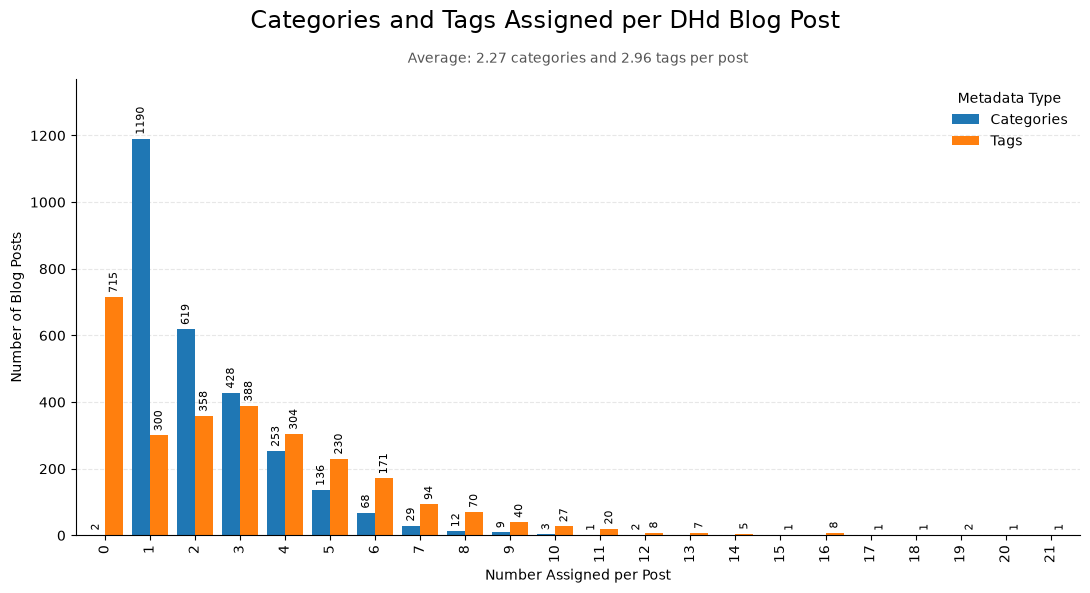

In [14]:
# Count categories and tags per post
category_count = (
    analysis_df["categories"].fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({v.strip() for v in x if v.strip()}))
)

tag_count = (
    analysis_df["tags"].fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({v.strip() for v in x if v.strip()}))
)

# Create one shared range
max_count = max(category_count.max(), tag_count.max())
count_range = range(0, max_count + 1)

comparison = pd.DataFrame({
    "Categories": category_count.value_counts().reindex(count_range, fill_value=0),
    "Tags": tag_count.value_counts().reindex(count_range, fill_value=0)
})

# Plot
fig, ax = plt.subplots(figsize=(11, 6))

comparison.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

# Vertical data labels
for container in ax.containers:
    labels = [
        f"{int(bar.get_height())}" if bar.get_height() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=3,
        rotation=90,
        fontsize=8
    )

fig.suptitle(
    "Categories and Tags Assigned per DHd Blog Post",
    fontsize=17,
    fontweight="normal"
)

ax.set_title(
    f"Average: {category_count.mean():.2f} categories and "
    f"{tag_count.mean():.2f} tags per post",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Number Assigned per Post")
ax.set_ylabel("Number of Blog Posts")

ax.legend(
    title="Metadata Type",
    frameon=False
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Extra space for labels above bars
ax.margins(y=0.15)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "categories_and_tags_per_post.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 18. Average Number of Tags and Categories per post per Year

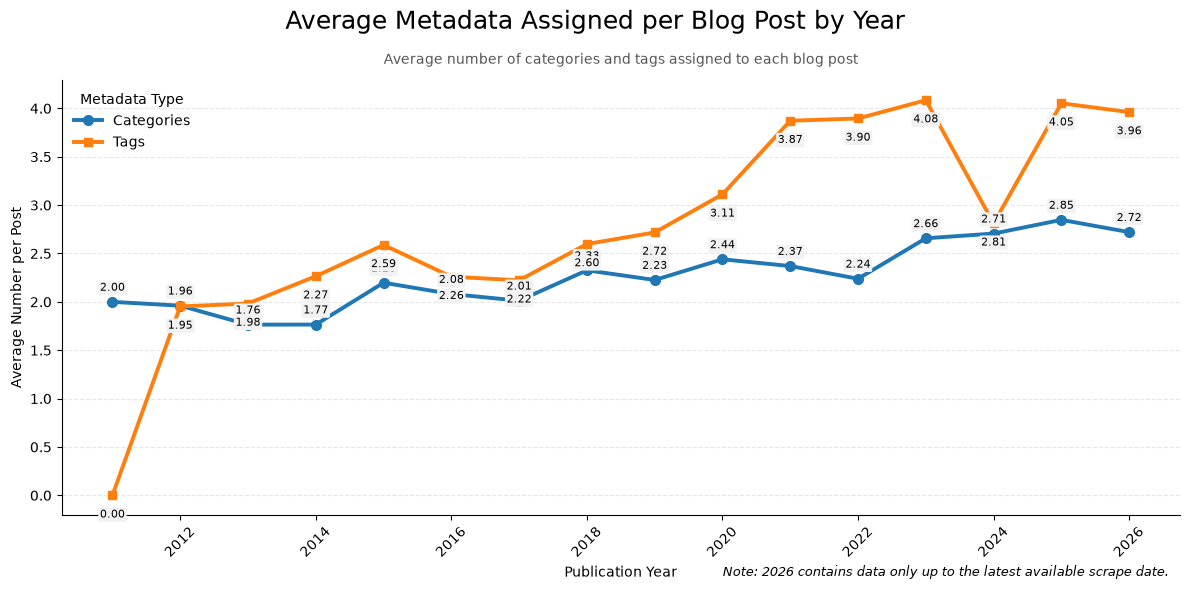

In [15]:
# ============================================================
# Average Categories & Tags per Post by Year
# ============================================================

# Categories per post
analysis_df["category_count"] = (
    analysis_df["categories"]
    .fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({c.strip() for c in x if c.strip()}))
)

# Tags per post
analysis_df["tag_count"] = (
    analysis_df["tags"]
    .fillna("")
    .str.split(r"\s*\|\s*")
    .apply(lambda x: len({t.strip() for t in x if t.strip()}))
)

# Yearly averages
yearly_avg = (
    analysis_df
    .groupby("year")[["category_count", "tag_count"]]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

# Categories
ax.plot(
    yearly_avg["year"],
    yearly_avg["category_count"],
    marker="o",
    linewidth=2.8,
    markersize=7,
    label="Categories"
)

# Tags
ax.plot(
    yearly_avg["year"],
    yearly_avg["tag_count"],
    marker="s",
    linewidth=2.8,
    markersize=6,
    label="Tags"
)

# Data labels
for _, row in yearly_avg.iterrows():

    ax.annotate(
        f"{row['category_count']:.2f}",
        (row["year"], row["category_count"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

    ax.annotate(
        f"{row['tag_count']:.2f}",
        (row["year"], row["tag_count"]),
        textcoords="offset points",
        xytext=(0, -16),
        ha="center",
        fontsize=8,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

fig.suptitle(
    "Average Metadata Assigned per Blog Post by Year",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    "Average number of categories and tags assigned to each blog post",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Publication Year")
ax.set_ylabel("Average Number per Post")

ax.legend(
    title="Metadata Type",
    frameon=False
)

ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", rotation=45)

if 2026 in yearly_avg["year"].values:
    ax.text(
        0.99,
        -0.14,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "average_metadata_per_post_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 19. Number of Unique Categories per Year

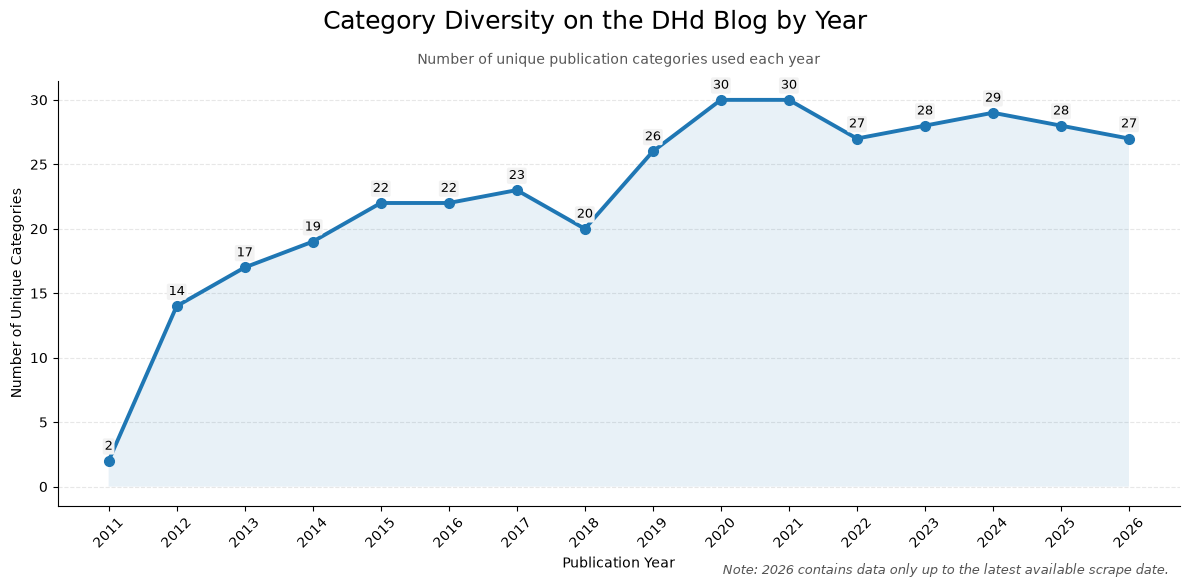

In [16]:
# Split categories into separate rows
category_year_df = (
    analysis_df[["year", "categories"]]
    .dropna(subset=["year"])
    .assign(
        category=lambda x:
        x["categories"].fillna("").str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_year_df["category"] = (
    category_year_df["category"]
    .fillna("")
    .str.strip()
)

category_year_df = category_year_df[
    category_year_df["category"] != ""
]

# Count unique categories per year
category_diversity = (
    category_year_df
    .groupby("year")["category"]
    .nunique()
    .reset_index(name="unique_categories")
)

category_diversity["year"] = (
    category_diversity["year"].astype(int)
)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    category_diversity["year"],
    category_diversity["unique_categories"],
    marker="o",
    linewidth=2.8,
    markersize=7
)

ax.fill_between(
    category_diversity["year"],
    category_diversity["unique_categories"],
    alpha=0.10
)

# Data labels
for _, row in category_diversity.iterrows():
    ax.annotate(
        f"{int(row['unique_categories'])}",
        (row["year"], row["unique_categories"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

fig.suptitle(
    "Category Diversity on the DHd Blog by Year",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    "Number of unique publication categories used each year",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Publication Year")
ax.set_ylabel("Number of Unique Categories")

ax.set_xticks(category_diversity["year"])
ax.tick_params(axis="x", rotation=45)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

if 2026 in category_diversity["year"].values:
    ax.text(
        0.99,
        -0.16,
        "Note: 2026 contains data only up to the latest available scrape date.",
        transform=ax.transAxes,
        ha="right",
        fontsize=9,
        style="italic",
        color="#555555"
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "category_diversity_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 20. Authors with the Longest Average Blog Posts

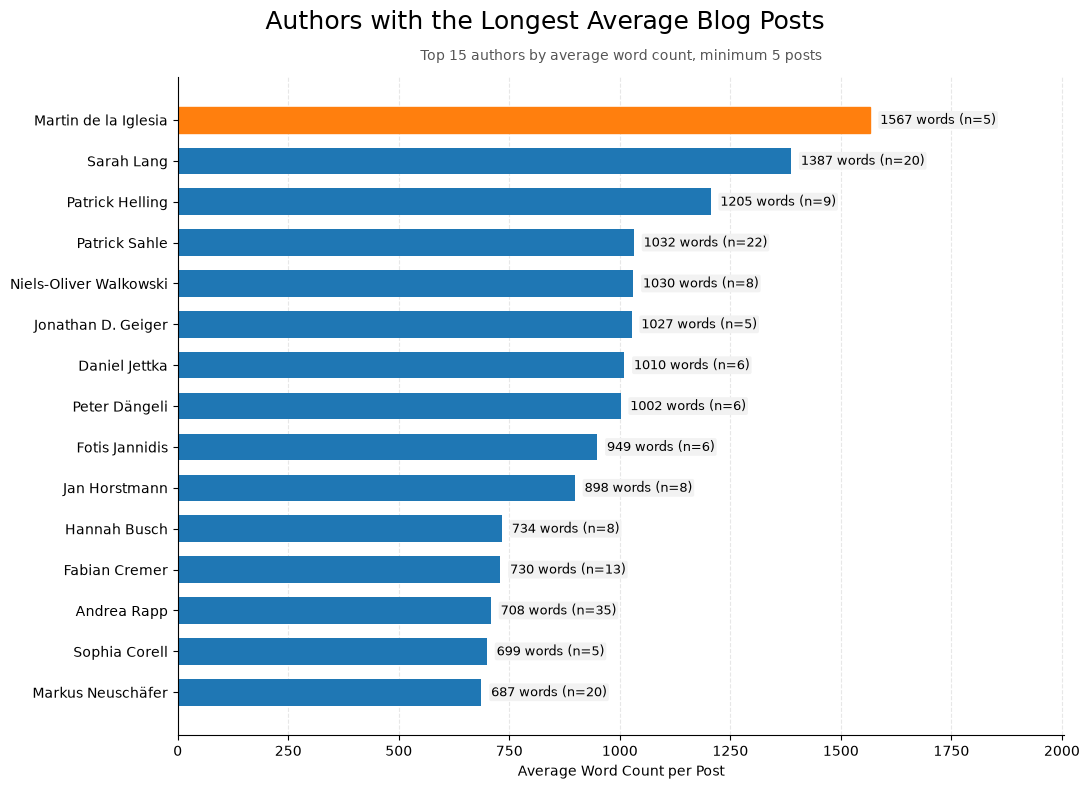

,author,posts,average_words
230,Martin de la Iglesia,5,1567.000000
310,Sarah Lang,20,1387.450000
277,Patrick Helling,9,1205.333333
278,Patrick Sahle,22,1031.863636
266,Niels-Oliver Walkowski,8,1030.375000
157,Jonathan D. Geiger,5,1026.600000
76,Daniel Jettka,6,1010.000000
283,Peter Dängeli,6,1001.666667
106,Fotis Jannidis,6,949.000000
136,Jan Horstmann,8,898.250000


In [17]:
# Prepare author statistics
author_word_stats = (
    analysis_df
    .assign(
        word_count=pd.to_numeric(
            analysis_df["word_count"],
            errors="coerce"
        )
    )
    .dropna(subset=["author", "word_count"])
    .groupby("author")
    .agg(
        posts=("word_count", "count"),
        average_words=("word_count", "mean")
    )
    .reset_index()
)

# Keep authors with at least 5 posts
MIN_POSTS = 5

top_authors = (
    author_word_stats[
        author_word_stats["posts"] >= MIN_POSTS
    ]
    .nlargest(15, "average_words")
    .sort_values("average_words")
)

# Plot
fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    top_authors["author"],
    top_authors["average_words"],
    height=0.65
)

# Highlight highest average
bars[-1].set_color("tab:orange")

# Labels: average words and number of posts
for bar, avg_words, posts in zip(
    bars,
    top_authors["average_words"],
    top_authors["posts"]
):
    ax.annotate(
        f"{avg_words:.0f} words (n={posts})",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        bbox=dict(
            facecolor="#f2f2f2",
            edgecolor="none",
            boxstyle="round,pad=0.15"
        )
    )

fig.suptitle(
    "Authors with the Longest Average Blog Posts",
    fontsize=18,
    fontweight="normal",
    y=0.98
)

ax.set_title(
    f"Top 15 authors by average word count, minimum {MIN_POSTS} posts",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Average Word Count per Post")
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(
    0,
    top_authors["average_words"].max() * 1.28
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "author_average_word_count.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    top_authors.sort_values(
        "average_words",
        ascending=False
    )
)


## 21. Monthly Publishing Patterns by Category


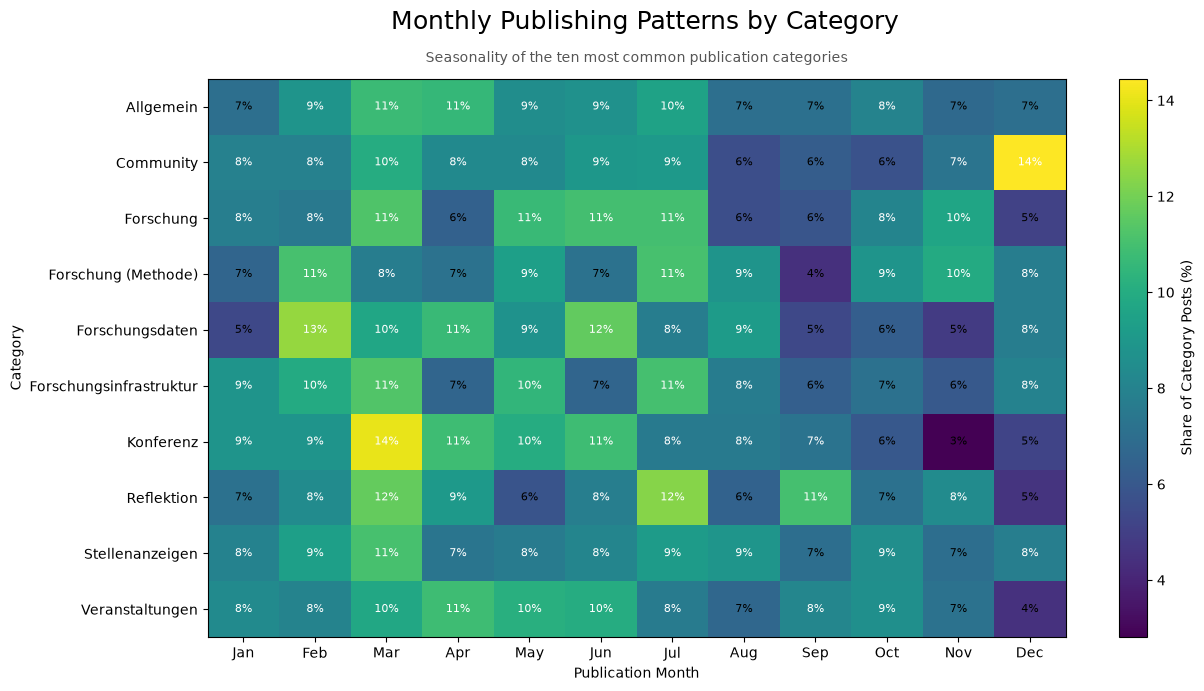

In [18]:
# ============================================================
# Monthly Publishing Patterns by Category
# ============================================================

month_labels = [
    "Jan","Feb","Mar","Apr","May","Jun",
    "Jul","Aug","Sep","Oct","Nov","Dec"
]

# Split categories
category_df = (
    analysis_df[
        ["post_id","month","categories"]
    ]
    .copy()
)

category_df["categories"] = (
    category_df["categories"]
    .fillna("")
    .str.split(r"\s*\|\s*")
)

category_df = category_df.explode("categories")

category_df["categories"] = (
    category_df["categories"]
    .str.strip()
)

category_df = category_df[
    category_df["categories"] != ""
]

# Keep Top 10 categories
top_categories = (
    category_df["categories"]
    .value_counts()
    .head(10)
    .index
)

category_df = category_df[
    category_df["categories"].isin(top_categories)
]

# Create matrix
heatmap = (
    category_df
    .groupby(["categories","month"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1,13),fill_value=0)
)

# Convert to %
heatmap = (
    heatmap
    .div(heatmap.sum(axis=1),axis=0)
    *100
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(13,7))

im = ax.imshow(
    heatmap,
    aspect="auto"
)

# Labels
ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(np.arange(len(heatmap.index)))
ax.set_yticklabels(heatmap.index)

# Cell labels
for i in range(len(heatmap.index)):
    for j in range(12):

        value = heatmap.iloc[i,j]

        ax.text(
            j,
            i,
            f"{value:.0f}%",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value>heatmap.values.max()/2 else "black"
        )

cbar = plt.colorbar(im)
cbar.set_label(
    "Share of Category Posts (%)"
)

fig.suptitle(
    "Monthly Publishing Patterns by Category",
    fontsize=18,
    fontweight="normal"
)

ax.set_title(
    "Seasonality of the ten most common publication categories",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Publication Month")
ax.set_ylabel("Category")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "monthly_category_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 22. Distribution of Digital Humanities research topics across the ten most common publication categories

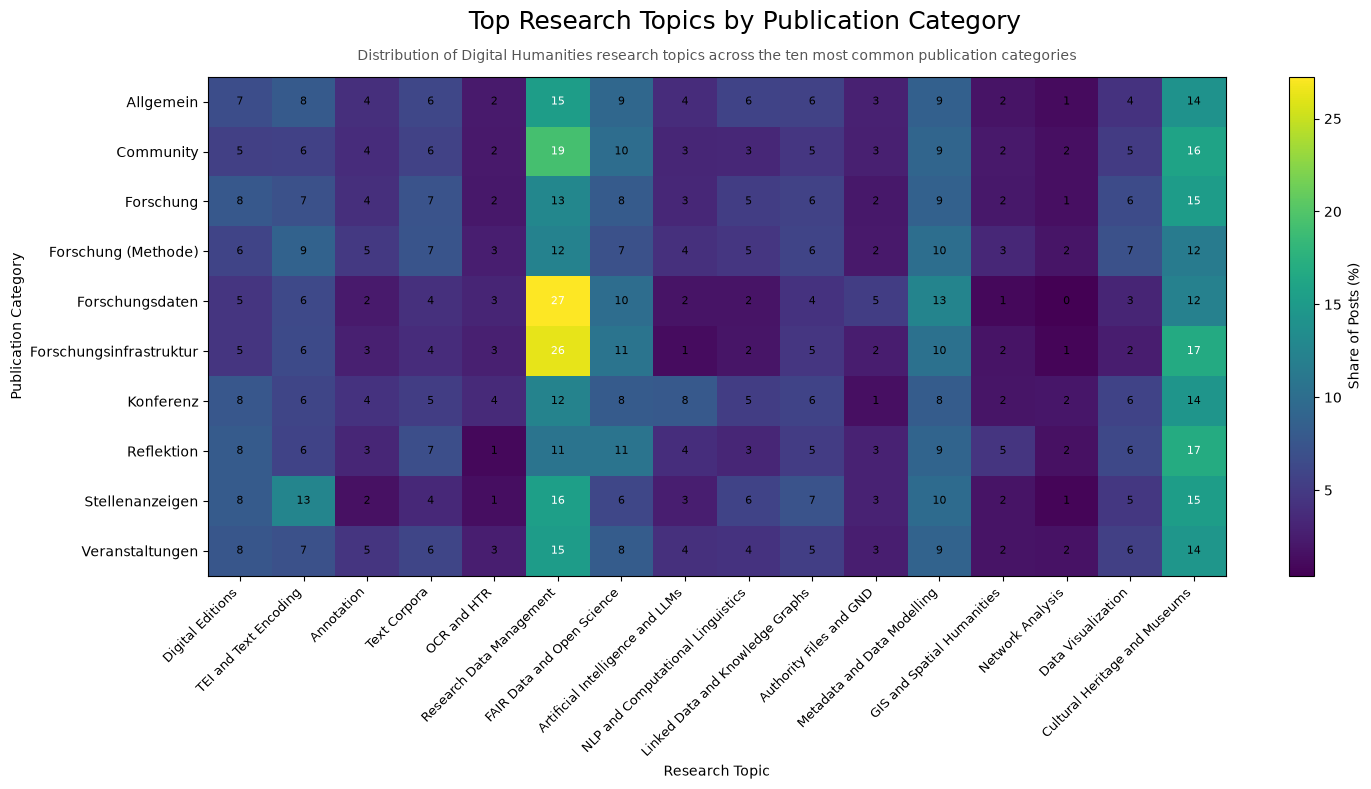

,Digital Editions,TEI and Text Encoding,Annotation,Text Corpora,OCR and HTR,Research Data Management,FAIR Data and Open Science,Artificial Intelligence and LLMs,NLP and Computational Linguistics,Linked Data and Knowledge Graphs,Authority Files and GND,Metadata and Data Modelling,GIS and Spatial Humanities,Network Analysis,Data Visualization,Cultural Heritage and Museums
Allgemein,161,192,97,148,57,369,226,91,139,138,68,207,43,28,104,338
Community,72,74,50,76,29,256,132,44,45,62,36,121,30,20,67,211
Forschung,58,52,30,54,16,95,60,25,39,42,16,65,16,11,48,113
Forschung (Methode),24,36,20,30,11,50,29,17,19,24,9,41,14,8,29,47
Forschungsdaten,23,32,12,21,16,139,51,9,9,22,27,64,5,2,16,62
Forschungsinfrastruktur,31,44,19,26,19,179,73,9,13,32,17,71,12,5,17,115
Konferenz,41,32,23,28,19,66,43,42,28,31,8,44,10,11,31,77
Reflektion,25,18,10,21,3,33,33,12,10,16,9,28,14,5,19,52
Stellenanzeigen,101,158,20,44,18,195,77,33,72,91,37,122,22,9,59,192
Veranstaltungen,113,106,68,90,39,228,124,62,65,80,39,135,27,25,83,217


In [19]:
# ============================================================
# PREPARE DATA
# ============================================================

category_topic_df = analysis_df.copy()

for col in ["categories", "title", "tags", "text"]:
    category_topic_df[col] = (
        category_topic_df[col]
        .fillna("")
        .astype(str)
    )

category_topic_df["search_text"] = (
    category_topic_df["title"] + " " +
    category_topic_df["tags"] + " " +
    category_topic_df["text"]
).str.lower()

# Split categories
category_topic_df = (
    category_topic_df
    .assign(
        category=lambda x:
        x["categories"].str.split(r"\s*\|\s*")
    )
    .explode("category")
)

category_topic_df["category"] = (
    category_topic_df["category"]
    .str.strip()
)

category_topic_df = category_topic_df[
    category_topic_df["category"] != ""
]

# Keep only top 10 categories
top_categories = (
    category_topic_df["category"]
    .value_counts()
    .head(10)
    .index
)

category_topic_df = category_topic_df[
    category_topic_df["category"].isin(top_categories)
]

# ============================================================
# DETECT RESEARCH TOPICS
# ============================================================

matrix = pd.DataFrame(
    0,
    index=sorted(top_categories),
    columns=topic_keywords.keys()
)

for topic, keywords in topic_keywords.items():

    pattern = "|".join(
        rf"(?<!\w){re.escape(k.lower())}(?!\w)"
        for k in keywords
    )

    matches = category_topic_df[
        category_topic_df["search_text"].str.contains(
            pattern,
            regex=True,
            na=False
        )
    ]

    counts = (
        matches
        .groupby("category")
        .size()
    )

    for cat, value in counts.items():
        matrix.loc[cat, topic] = value

# Convert to row percentages
matrix_pct = (
    matrix
    .div(matrix.sum(axis=1), axis=0)
    * 100
).fillna(0)

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(15,8))

im = ax.imshow(
    matrix_pct.values,
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(matrix_pct.columns))
)

ax.set_xticklabels(
    matrix_pct.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticks(
    np.arange(len(matrix_pct.index))
)

ax.set_yticklabels(
    matrix_pct.index,
    fontsize=10
)

# Cell values
mx = matrix_pct.values.max()

for i in range(matrix_pct.shape[0]):
    for j in range(matrix_pct.shape[1]):

        value = matrix_pct.iloc[i, j]

        if value > 0:

            ax.text(
                j,
                i,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value > mx * 0.55 else "black"
            )

cbar = plt.colorbar(im)
cbar.set_label("Share of Posts (%)")

fig.suptitle(
    "Top Research Topics by Publication Category",
    fontsize=18,
    fontweight="normal"
)

ax.set_title(
    "Distribution of Digital Humanities research topics across the ten most common publication categories",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Research Topic")
ax.set_ylabel("Publication Category")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_research_topics_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(matrix.sort_index())


## 23. How frequently Digital Humanities research topics appear together in the same blog post

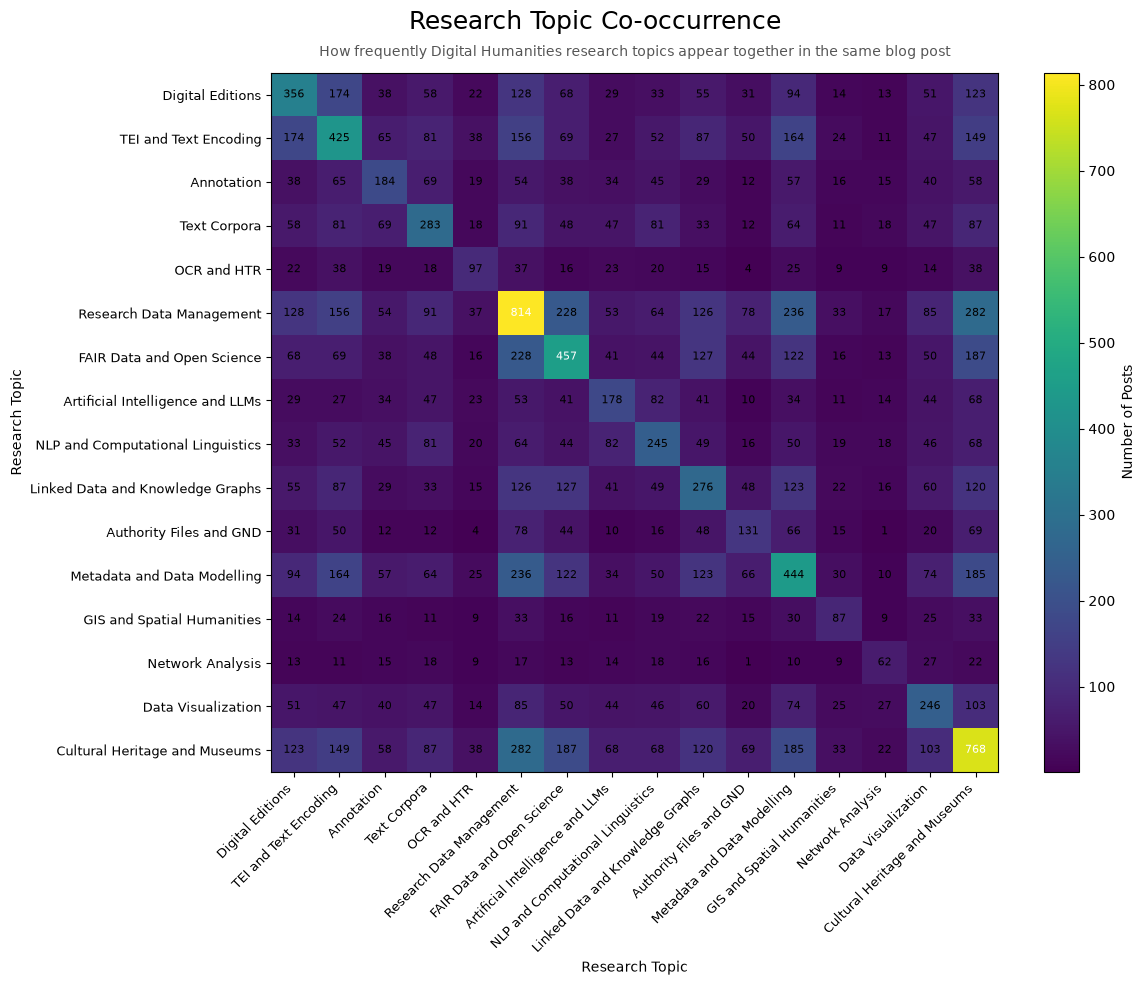

,Digital Editions,TEI and Text Encoding,Annotation,Text Corpora,OCR and HTR,Research Data Management,FAIR Data and Open Science,Artificial Intelligence and LLMs,NLP and Computational Linguistics,Linked Data and Knowledge Graphs,Authority Files and GND,Metadata and Data Modelling,GIS and Spatial Humanities,Network Analysis,Data Visualization,Cultural Heritage and Museums
Digital Editions,356,174,38,58,22,128,68,29,33,55,31,94,14,13,51,123
TEI and Text Encoding,174,425,65,81,38,156,69,27,52,87,50,164,24,11,47,149
Annotation,38,65,184,69,19,54,38,34,45,29,12,57,16,15,40,58
Text Corpora,58,81,69,283,18,91,48,47,81,33,12,64,11,18,47,87
OCR and HTR,22,38,19,18,97,37,16,23,20,15,4,25,9,9,14,38
Research Data Management,128,156,54,91,37,814,228,53,64,126,78,236,33,17,85,282
FAIR Data and Open Science,68,69,38,48,16,228,457,41,44,127,44,122,16,13,50,187
Artificial Intelligence and LLMs,29,27,34,47,23,53,41,178,82,41,10,34,11,14,44,68
NLP and Computational Linguistics,33,52,45,81,20,64,44,82,245,49,16,50,19,18,46,68
Linked Data and Knowledge Graphs,55,87,29,33,15,126,127,41,49,276,48,123,22,16,60,120


In [20]:
# ============================================================
# Research Topic Co-occurrence
# ============================================================

topic_df = analysis_df.copy()

for col in ["title", "tags", "text", "categories"]:
    topic_df[col] = (
        topic_df[col]
        .fillna("")
        .astype(str)
    )

topic_df["search_text"] = (
    topic_df["title"] + " " +
    topic_df["tags"] + " " +
    topic_df["categories"] + " " +
    topic_df["text"]
).str.lower()

# Detect topics
topic_presence = pd.DataFrame(index=topic_df.index)

for topic, keywords in topic_keywords.items():

    pattern = "|".join(
        rf"(?<!\w){re.escape(k.lower())}(?!\w)"
        for k in keywords
    )

    topic_presence[topic] = topic_df["search_text"].str.contains(
        pattern,
        regex=True,
        na=False
    )

# Co-occurrence matrix
co_matrix = (
    topic_presence.astype(int).T
    @ topic_presence.astype(int)
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(12,10))

im = ax.imshow(
    co_matrix.values,
    aspect="auto"
)

ax.set_xticks(np.arange(len(co_matrix.columns)))
ax.set_xticklabels(
    co_matrix.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticks(np.arange(len(co_matrix.index)))
ax.set_yticklabels(
    co_matrix.index,
    fontsize=9
)

# Values
mx = co_matrix.values.max()

for i in range(co_matrix.shape[0]):
    for j in range(co_matrix.shape[1]):

        value = co_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            str(value),
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > mx*0.55 else "black"
        )

cbar = plt.colorbar(im)
cbar.set_label("Number of Posts")

fig.suptitle(
    "Research Topic Co-occurrence",
    fontsize=18,
    fontweight="normal"
)

ax.set_title(
    "How frequently Digital Humanities research topics appear together in the same blog post",
    fontsize=10,
    color="#555555",
    pad=12
)

ax.set_xlabel("Research Topic")
ax.set_ylabel("Research Topic")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "research_topic_cooccurrence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(co_matrix)
